# Comorbidity Network Analysis Pipeline

This notebook reproduces the full analysis pipeline described in: *"Enhancing comorbidity network inference with risk-enriched health trajectories embedding"*

**Pipeline steps:**
1. Data import, preprocessing, and sequence visualization
2. Word embedding (BioWordVec fine-tuning)
3. Cosine-similarity matrices
4. Comparison, risk-factor analysis, and sensitivity analysis
5. Network sparsification via Graphical Lasso (GGM)
6. GGM network visualization
7. Topological analysis and community detection

**NOTE (Simulated data):** When `DATA_MODE = "simulated"`, the pipeline
runs on synthetic data generated by `simulate_sequences.py`. Simulated
patients do not represent real individuals. Network structures will differ
from the original publication results.


## Section 0 — Configuration

Set `DATA_MODE = "simulated"` to use the synthetic sequences generated by
`simulate_sequences.py` (run it first: `python simulate_sequences.py`).
Set `DATA_MODE = "real"` and fill in the paths below to use your own data.
The real-data files must have columns: `ID`, `age_in_days_since_born`, `event_name`.

In [4]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns
import networkx as nx
from scipy.spatial.distance import cosine
from scipy.stats import mannwhitneyu, pearsonr, spearmanr
from scipy.special import erfc
from sklearn.covariance import GraphicalLassoCV
try:
    from sklearn.metrics.pairwise import cosine_similarity as sk_cosine_similarity
except Exception:
    # Fallback using scipy (works with older sklearn versions)
    from scipy.spatial.distance import cdist
    def sk_cosine_similarity(X):
        return 1 - cdist(X, X, metric="cosine")

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 120})

# ── User configuration ────────────────────────────────────────────────────────
DATA_MODE = "simulated"   # "simulated" | "real"

# Paths for real data (only used when DATA_MODE = "real")
REAL_MAIN_SEQ_PATH     = None   #None e.g. "/path/to/sequence_main_final.csv"
REAL_PARALLEL_SEQ_PATH = None   #None e.g. "/path/to/sequence_parallel_final.csv"

# Output directories
OUTPUT_PLOTS_DIR = "plots"
OUTPUT_GGM_DIR   = "results_GGM"
OUTPUT_BASE_DIR  = "Baseline"
os.makedirs(OUTPUT_PLOTS_DIR, exist_ok=True)
os.makedirs(OUTPUT_GGM_DIR,   exist_ok=True)
os.makedirs(OUTPUT_BASE_DIR,  exist_ok=True)

print(f"DATA_MODE = {DATA_MODE}")
print("Configuration loaded.")


DATA_MODE = simulated
Configuration loaded.


## Section 1 — Data Import and Preprocessing

### 1.1  Load sequences

Simulated sequences are produced by `simulate_sequences.py`.
Both files share the same column schema:

| Column | Description |
|---|---|
| `ID` | Patient identifier |
| `age_in_days_since_born` | Age at event (days) |
| `event_name` | MeSH disease / risk-factor name |


In [5]:
if DATA_MODE == "simulated":
    MAIN_PATH     = os.path.join("/group/diangelantonio/users/alessia_mapelli/Complete_projects/Com_network_NLP/data_simulated", "sequence_main_simulated.csv")
    PARALLEL_PATH = os.path.join("/group/diangelantonio/users/alessia_mapelli/Complete_projects/Com_network_NLP/data_simulated", "sequence_parallel_simulated.csv")
else:
    MAIN_PATH     = REAL_MAIN_SEQ_PATH
    PARALLEL_PATH = REAL_PARALLEL_SEQ_PATH

df_main     = pd.read_csv(MAIN_PATH)
df_parallel = pd.read_csv(PARALLEL_PATH)

print(f"Main sequence:     {df_main.shape[0]:,} rows  |  {df_main['ID'].nunique():,} unique patients")
print(f"Parallel sequence: {df_parallel.shape[0]:,} rows  |  {df_parallel['ID'].nunique():,} unique patients")
df_main.head(3)


Main sequence:     35,637 rows  |  5,000 unique patients
Parallel sequence: 530,066 rows  |  5,000 unique patients


,ID,age_in_days_since_born,event_name
0,1,20976,Diabetes Mellitus
1,1,21997,Hypertension
2,1,28480,"Kidney Diseases, Chronic, Stage 3"


### 1.2  Filtering

* Remove events at age = 0 from the main sequence.
* Retain only patients with **≥ 3 distinct disease events** (mirrors the real-data cohort criterion).

In [6]:
# Remove age-0 entries from main sequence
df_main = df_main[df_main["age_in_days_since_born"] > 0].copy()

# Keep patients with ≥ 3 distinct disease events
counts   = df_main.groupby("ID")["event_name"].nunique()
keep_ids = counts[counts >= 3].index
df_main     = df_main[df_main["ID"].isin(keep_ids)].copy()
df_parallel = df_parallel[df_parallel["ID"].isin(keep_ids)].copy()

print(f"After filtering:")
print(f"  Main sequence:     {len(df_main):,} rows  |  {df_main['ID'].nunique():,} patients")
print(f"  Parallel sequence: {len(df_parallel):,} rows  |  {df_parallel['ID'].nunique():,} patients")


After filtering:
  Main sequence:     33,918 rows  |  4,492 patients
  Parallel sequence: 501,593 rows  |  4,492 patients


### 1.3  Build final sequence DataFrames

Save the processed sequences for downstream steps.

In [7]:
# Main-only events (sorted by patient and age)
sequence_main_final = (
    df_main
    .sort_values(["ID", "age_in_days_since_born"])
    .reset_index(drop=True)
)

# Main + parallel (concatenate and sort)
sequence_main_parr_final = (
    pd.concat([sequence_main_final, df_parallel])
    .sort_values(["ID", "age_in_days_since_born"])
    .reset_index(drop=True)
)

sequence_main_final.to_csv("sequence_main_final.csv", index=False)
sequence_main_parr_final.to_csv("sequence_main_parr_final.csv", index=False)

print(f"sequence_main_final:      {len(sequence_main_final):,} rows")
print(f"sequence_main_parr_final: {len(sequence_main_parr_final):,} rows")


sequence_main_final:      33,918 rows
sequence_main_parr_final: 535,511 rows


### 1.5  Cohort summary statistics

In [8]:
n_patients = sequence_main_final["ID"].nunique()
data_unique = sequence_main_final.groupby(["ID", "event_name"], as_index=False).first()

incidence_df = (
    data_unique.groupby("event_name")["ID"].nunique()
    .reset_index(name="n_patients_with_disease")
    .assign(incidence_pct=lambda x: x["n_patients_with_disease"] / n_patients * 100)
    .sort_values("incidence_pct", ascending=False)
    .reset_index(drop=True)
)
print(f"Total patients: {n_patients:,}")
print(f"Total main-sequence events: {len(sequence_main_final):,}")
display(incidence_df.style.format({"incidence_pct": "{:.1f}%"}))


Total patients: 4,492
Total main-sequence events: 33,918


,event_name,n_patients_with_disease,incidence_pct
0,Hypertension,4373,97.4%
1,Dyslipidemias,3559,79.2%
2,Coronary Disease,2346,52.2%
3,Diabetes Mellitus,1826,40.7%
4,Atrial Fibrillation,1470,32.7%
5,Cerebrovascular Disorders,985,21.9%
6,Acute Kidney Injury,970,21.6%
7,"Kidney Diseases, Chronic, Stage 3",881,19.6%
8,Heart Failure,872,19.4%
9,"Pacemaker, Artificial",500,11.1%


### 1.6  Visualizations

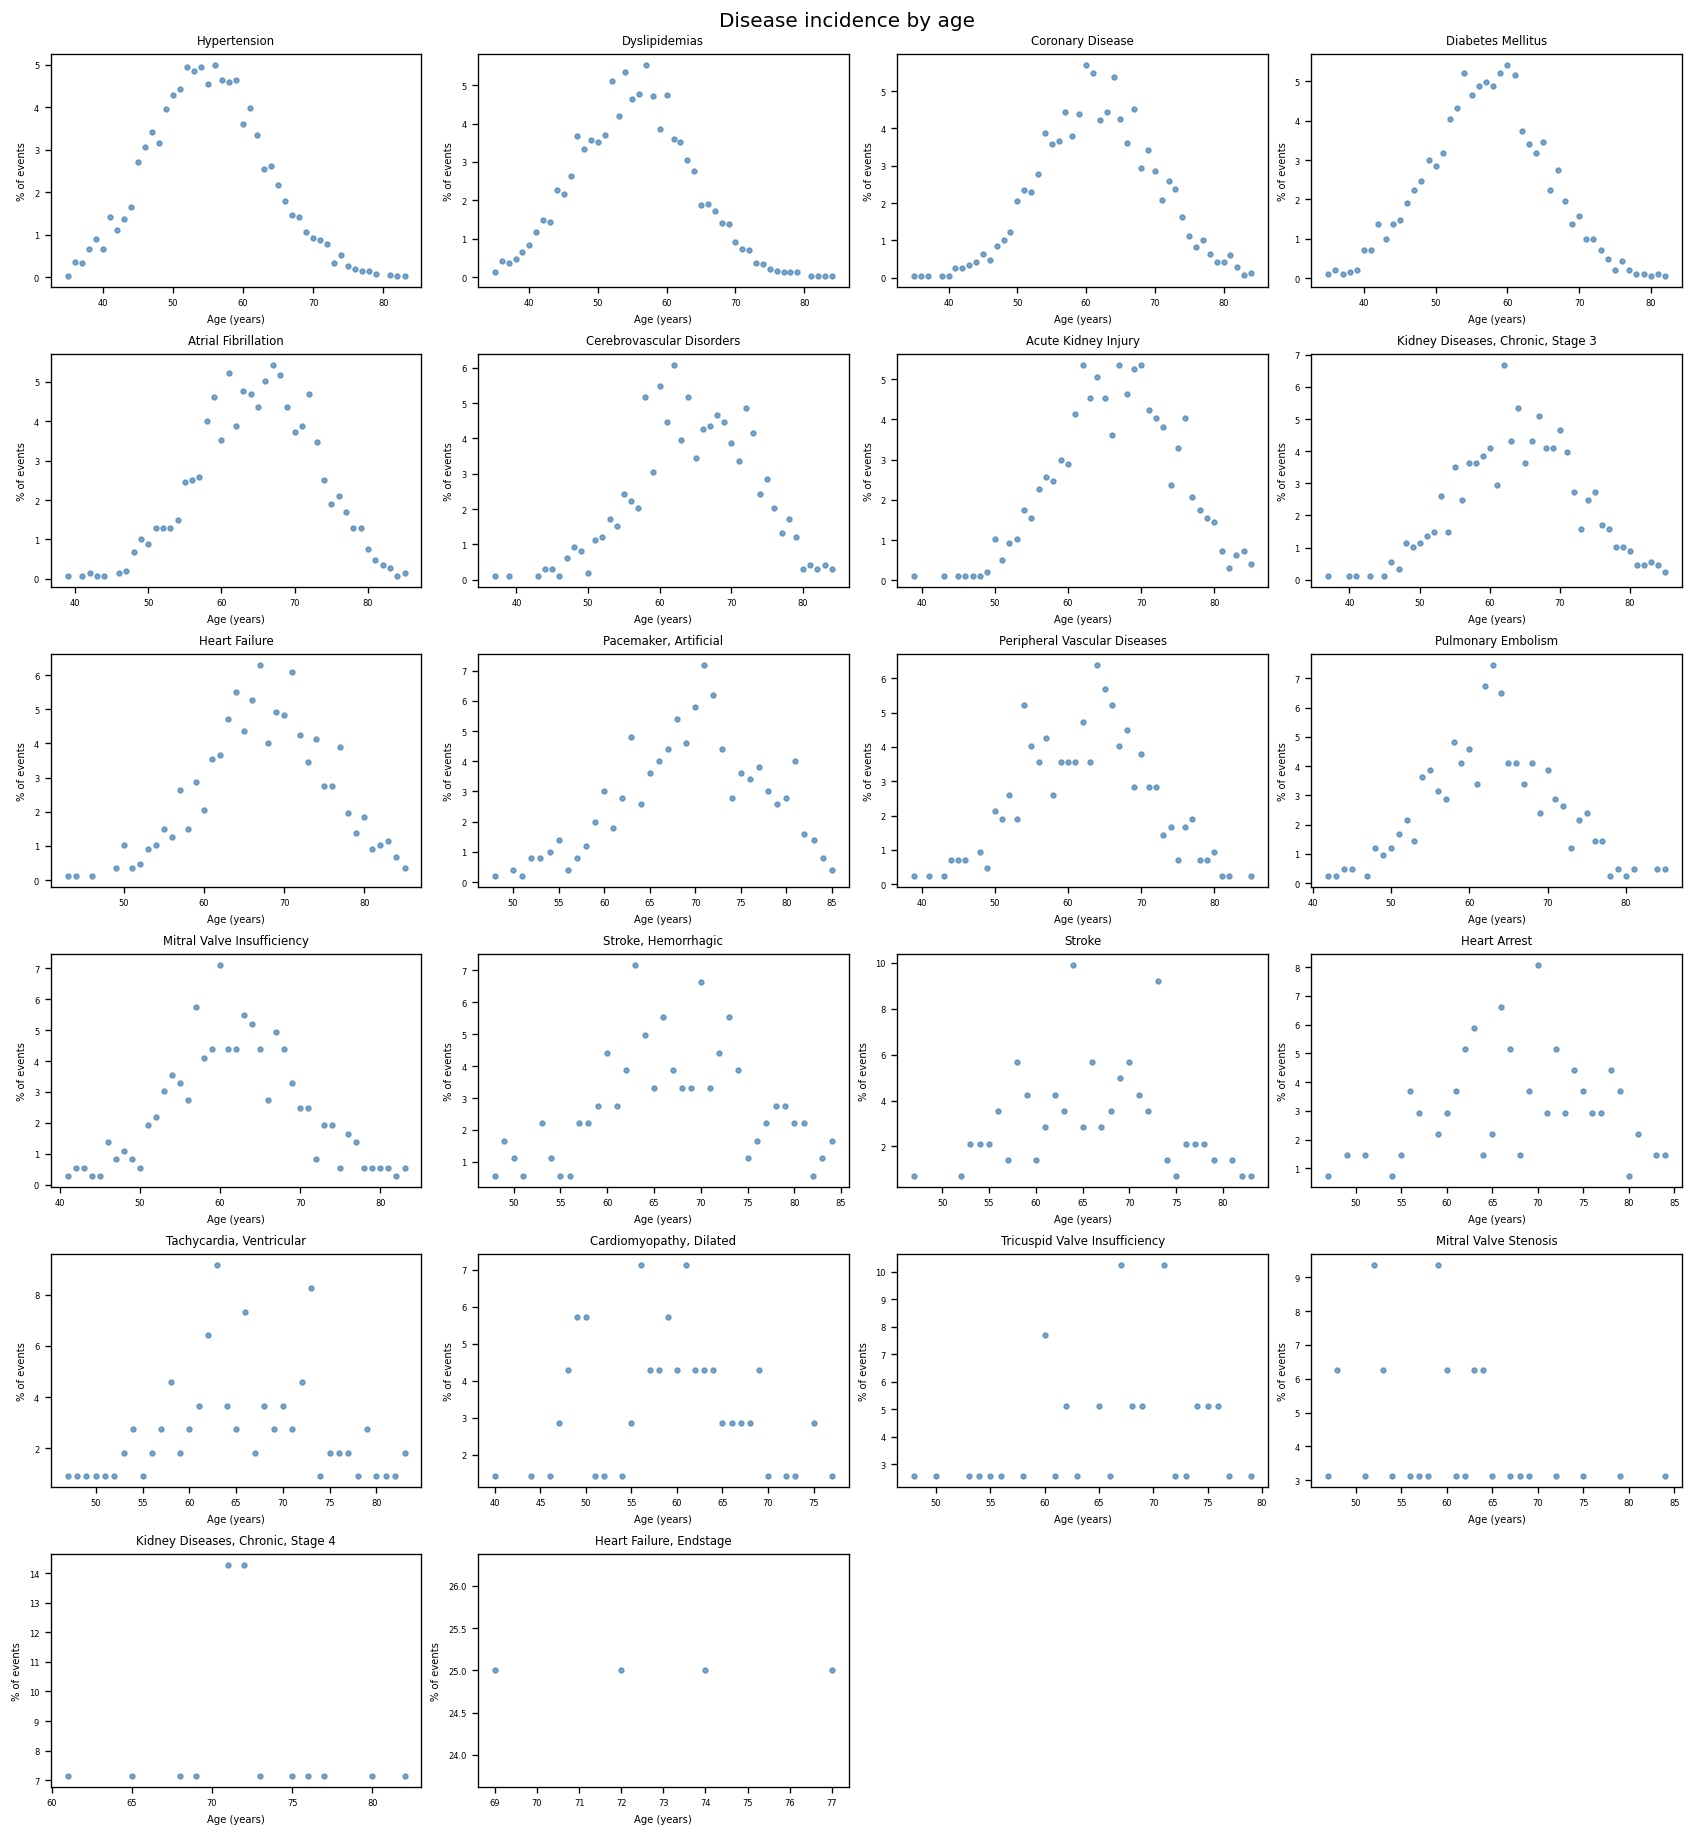

Saved: disease_incidence_by_age.png / .svg


In [9]:
# ── Plot 1: Disease incidence by age (6×4 faceted) ──────────────────────────
# First incidence per patient per disease, convert to years
first_incidence = (
    sequence_main_final
    .sort_values(["ID", "age_in_days_since_born"])
    .groupby(["ID", "event_name"], as_index=False)
    .first()
)
first_incidence["age_yr"] = np.round(
    first_incidence["age_in_days_since_born"] / 365
).astype(int)

age_dist = (
    first_incidence
    .groupby(["event_name", "age_yr"])
    .size()
    .reset_index(name="N")
)
total_per_disease = age_dist.groupby("event_name")["N"].sum().reset_index(name="total")
age_dist = age_dist.merge(total_per_disease, on="event_name")
age_dist["pct"] = age_dist["N"] / age_dist["total"] * 100

diseases_sorted = incidence_df["event_name"].tolist()
n_diseases = len(diseases_sorted)
ncols, nrows = 4, int(np.ceil(n_diseases / 4))

fig, axes = plt.subplots(nrows, ncols, figsize=(14, nrows * 2.5), constrained_layout=True)
axes = axes.flatten()

for ax, disease in zip(axes, diseases_sorted):
    sub = age_dist[age_dist["event_name"] == disease]
    ax.scatter(sub["age_yr"], sub["pct"], color="steelblue", s=8, alpha=0.7)
    ax.set_title(disease, fontsize=7, wrap=True)
    ax.set_xlabel("Age (years)", fontsize=6)
    ax.set_ylabel("% of events", fontsize=6)
    ax.tick_params(labelsize=5)

for ax in axes[n_diseases:]:
    ax.set_visible(False)

fig.suptitle("Disease incidence by age", fontsize=12, y=1.01)
fig.savefig(os.path.join(OUTPUT_PLOTS_DIR, "disease_incidence_by_age.png"),
            dpi=200, bbox_inches="tight")
fig.savefig(os.path.join(OUTPUT_PLOTS_DIR, "disease_incidence_by_age.svg"),
            format="svg", bbox_inches="tight")
plt.show()
print("Saved: disease_incidence_by_age.png / .svg")


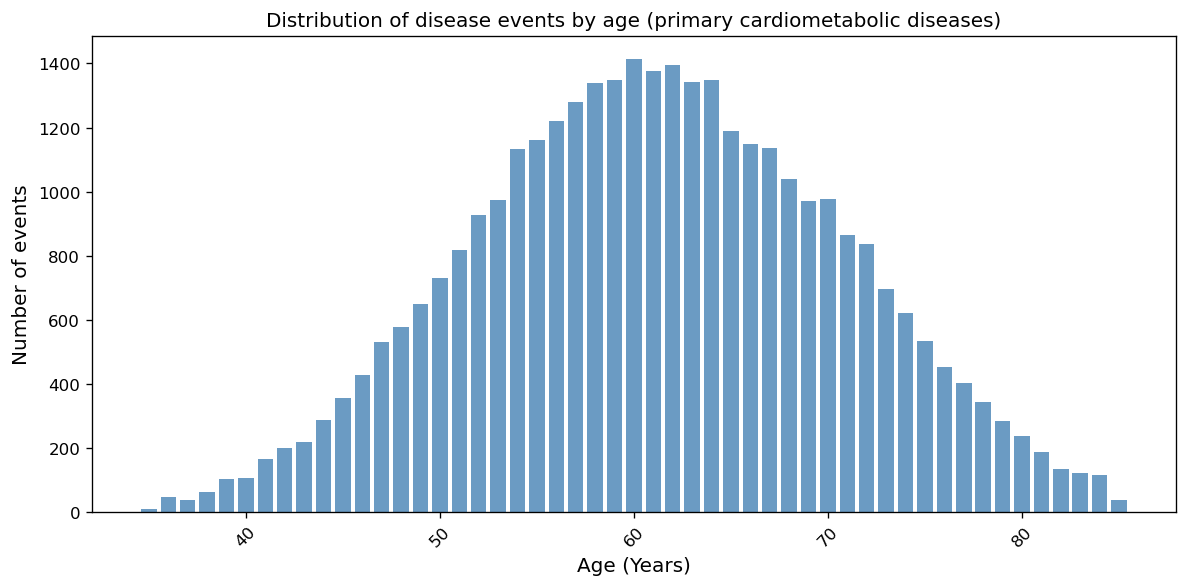

Saved: total_events_by_age.png / .svg


In [10]:
# ── Plot 2: Total disease events distribution by age ─────────────────────────
all_events_age = sequence_main_final.copy()
all_events_age["age_yr"] = np.round(
    all_events_age["age_in_days_since_born"] / 365
).astype(int)

total_by_age = all_events_age.groupby("age_yr").size().reset_index(name="N")

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(total_by_age["age_yr"], total_by_age["N"], color="steelblue", alpha=0.8)
ax.set_xlabel("Age (Years)", fontsize=12)
ax.set_ylabel("Number of events", fontsize=12)
ax.set_title("Distribution of disease events by age (primary cardiometabolic diseases)",
             fontsize=12)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_PLOTS_DIR, "total_events_by_age.png"),
            dpi=200, bbox_inches="tight")
fig.savefig(os.path.join(OUTPUT_PLOTS_DIR, "total_events_by_age.svg"),
            format="svg", bbox_inches="tight")
plt.show()
print("Saved: total_events_by_age.png / .svg")


## Section 2 — Word Embedding

> **Pre-trained model**
>
> This section requires the BioWordVec base model (`pubmed_mesh_test`).
> If you have not already trained it, run from a terminal **before** executing
> this section:
>
> ```bash
> python BioWordVec.py
> ```
>
> Training takes ~15–30 minutes depending on hardware. The model files
> (`pubmed_mesh_test`, `pubmed_mesh_test.bin`) will be saved in the current
> directory.


In [21]:
DISEASE_NAMES_MAIN = [n for n in df_main["event_name"].unique()]
RF_NAMES=[n for n in df_parallel["event_name"].unique()]
PHRASES_ALL = DISEASE_NAMES_MAIN + RF_NAMES   # full vocabulary
print(f"Total vocabulary size: {len(PHRASES_ALL)}")

Total vocabulary size: 103


In [11]:
from pathlib import Path
from gensim.models import FastText

PRETRAINED_MODEL_PATH  = "./pubmed_mesh_test"
FINETUNED_MAIN_PATH    = "./pubmed_mesh_finetuned_main"
FINETUNED_MAINPAR_PATH = "./pubmed_mesh_finetuned_main_par"

if not Path(PRETRAINED_MODEL_PATH).exists():
    raise FileNotFoundError(
        "Pre-trained model not found at './pubmed_mesh_test'.\n"
        "Run:  python BioWordVec.py\n"
        "then re-execute this cell."
    )
print("Pre-trained BioWordVec model found.")
base_model = FastText.load(PRETRAINED_MODEL_PATH)
print(f"  Vector size: {base_model.vector_size}  |  Vocab size: {len(base_model.wv)}")


Pre-trained BioWordVec model found.
  Vector size: 200  |  Vocab size: 65158


> **Fine-tuning hyperparameters**
>
> Adjust the `FINETUNE_EPOCHS` parameter below before running the fine-tuning cells.
> Note: More epochs → better sequence adaptation, less domain contribution, longer runtime



In [12]:
FINETUNE_EPOCHS  = 4    # in the paper choosed based on embedding-similarity between original and fine-tuned model

In [13]:
def build_corpus(seq_df: pd.DataFrame, phrase_col: str = "event_name") -> list:
    corpus = []
    for pid, grp in seq_df.sort_values("age_in_days_since_born").groupby("ID"):
        tokens = []
        for phrase in grp[phrase_col]:
            # Split multi-word MeSH terms into individual tokens
            tokens.extend(phrase.replace(",", "").lower().split())
        if tokens:
            corpus.append(tokens)
    return corpus

corpus_main    = build_corpus(sequence_main_final)
corpus_mainpar = build_corpus(sequence_main_parr_final)
print(f"Corpus (main):         {len(corpus_main):,} sentences")
print(f"Corpus (main+parallel): {len(corpus_mainpar):,} sentences")
print(f"Example sentence (main): {corpus_main[0][:10]} …")


Corpus (main):         4,492 sentences
Corpus (main+parallel): 4,492 sentences
Example sentence (main): ['diabetes', 'mellitus', 'hypertension', 'kidney', 'diseases', 'chronic', 'stage', '3', 'kidney', 'diseases'] …


In [16]:
# Fine-tune on main sequence
import copy
print("Fine-tuning on main sequence …")
model_main = copy.deepcopy(base_model)
model_main.build_vocab(corpus_main, update=True)
model_main.train(corpus_main,
                 total_examples=len(corpus_main),
                 epochs=FINETUNE_EPOCHS)
model_main.save(FINETUNED_MAIN_PATH)
print(f"  Saved → {FINETUNED_MAIN_PATH}")


Fine-tuning on main sequence …
  Saved → ./pubmed_mesh_finetuned_main


In [17]:
# Fine-tune on main + parallel sequence 
print("Fine-tuning on main + parallel sequence …")
model_mainpar = copy.deepcopy(base_model)
model_mainpar.build_vocab(corpus_mainpar, update=True)
model_mainpar.train(corpus_mainpar,
                    total_examples=len(corpus_mainpar),
                    epochs=FINETUNE_EPOCHS)
model_mainpar.save(FINETUNED_MAINPAR_PATH)
print(f"  Saved → {FINETUNED_MAINPAR_PATH}")


Fine-tuning on main + parallel sequence …
  Saved → ./pubmed_mesh_finetuned_main_par


### 2.1  Extract events embeddings

For each disease / risk-factor phrase, we average its word-level embeddings to obtain a
phrase-level vector.

In [31]:
def phrase_vector(phrase: str, model) -> np.ndarray:
    """Average embedding for a multi-word MeSH phrase"""
    tokens = phrase.replace(",", "").lower().split()
    vecs   = [model.wv.get_vector(t, norm=True) for t in tokens]
    return np.mean(vecs, axis=0)

def get_phrase_vectors(phrases: list, model) -> np.ndarray:
    """Return (n_phrases × vector_size) array of phrase embeddings."""
    return np.array([phrase_vector(p, model) for p in phrases])


print("Building embedding matrix (main + parallel) …")
phrase_emb_df = pd.DataFrame(get_phrase_vectors(PHRASES_ALL, model_mainpar))
phrase_emb_df.index = PHRASES_ALL
phrase_emb_df.to_csv("phrase_embeddings_main_par_df.csv")
print(f"Embedding matrix shape: {phrase_emb_df.shape}  (phrases x emb_dimention)")
phrase_emb_df.head(3)


Building embedding matrix (main + parallel) …
Embedding matrix shape: (103, 200)  (phrases x emb_dimention)


,0,1,2,3,4,5,6,7,8,9,...,190,191,192,193,194,195,196,197,198,199
Diabetes Mellitus,-0.115849,0.031827,0.017982,-0.052284,0.116841,0.077419,0.011351,-0.030530,-0.020779,0.052225,...,0.007448,-0.032169,0.016342,-0.161375,-0.041892,0.041913,-0.101397,0.037461,-0.081461,0.018281
Hypertension,-0.104739,0.036911,-0.014939,-0.045213,0.073185,0.098101,-0.006063,-0.024779,-0.030571,0.061348,...,0.012518,-0.050479,0.036019,-0.190382,-0.035776,0.058016,-0.137162,0.012991,-0.060949,0.023258
"Kidney Diseases, Chronic, Stage 3",-0.019570,-0.005847,0.022179,-0.049880,0.080760,0.100559,0.038013,0.011722,-0.036527,0.037798,...,0.005935,-0.053396,0.051763,-0.122304,-0.026834,0.045825,-0.091552,0.019375,-0.008498,0.025774


## Section 3 — Similarity Construction and Visualization

In [36]:
vecs_main    = get_phrase_vectors(DISEASE_NAMES_MAIN, model_main)
sim_main_arr = sk_cosine_similarity(vecs_main)
sim_main_df  = pd.DataFrame(sim_main_arr,
                             index=DISEASE_NAMES_MAIN,
                             columns=DISEASE_NAMES_MAIN)

vecs_all         = get_phrase_vectors(PHRASES_ALL, model_mainpar)
sim_all_arr      = sk_cosine_similarity(vecs_all)
sim_all_df       = pd.DataFrame(sim_all_arr, index=PHRASES_ALL, columns=PHRASES_ALL)

sim_mainpar_24_df = sim_all_df.loc[DISEASE_NAMES_MAIN, DISEASE_NAMES_MAIN]

# ── Global vmin / vmax across both 24×24 matrices (consistent colour scale) ──
_vals  = np.concatenate([sim_main_arr.flatten(),
                          sim_mainpar_24_df.values.flatten()])
VMIN_SIM = float(np.min(_vals))
VMAX_SIM = float(np.max(_vals))
print(f"Similarity range (both models): [{VMIN_SIM:.3f}, {VMAX_SIM:.3f}]")


Similarity range (both models): [0.562, 1.000]


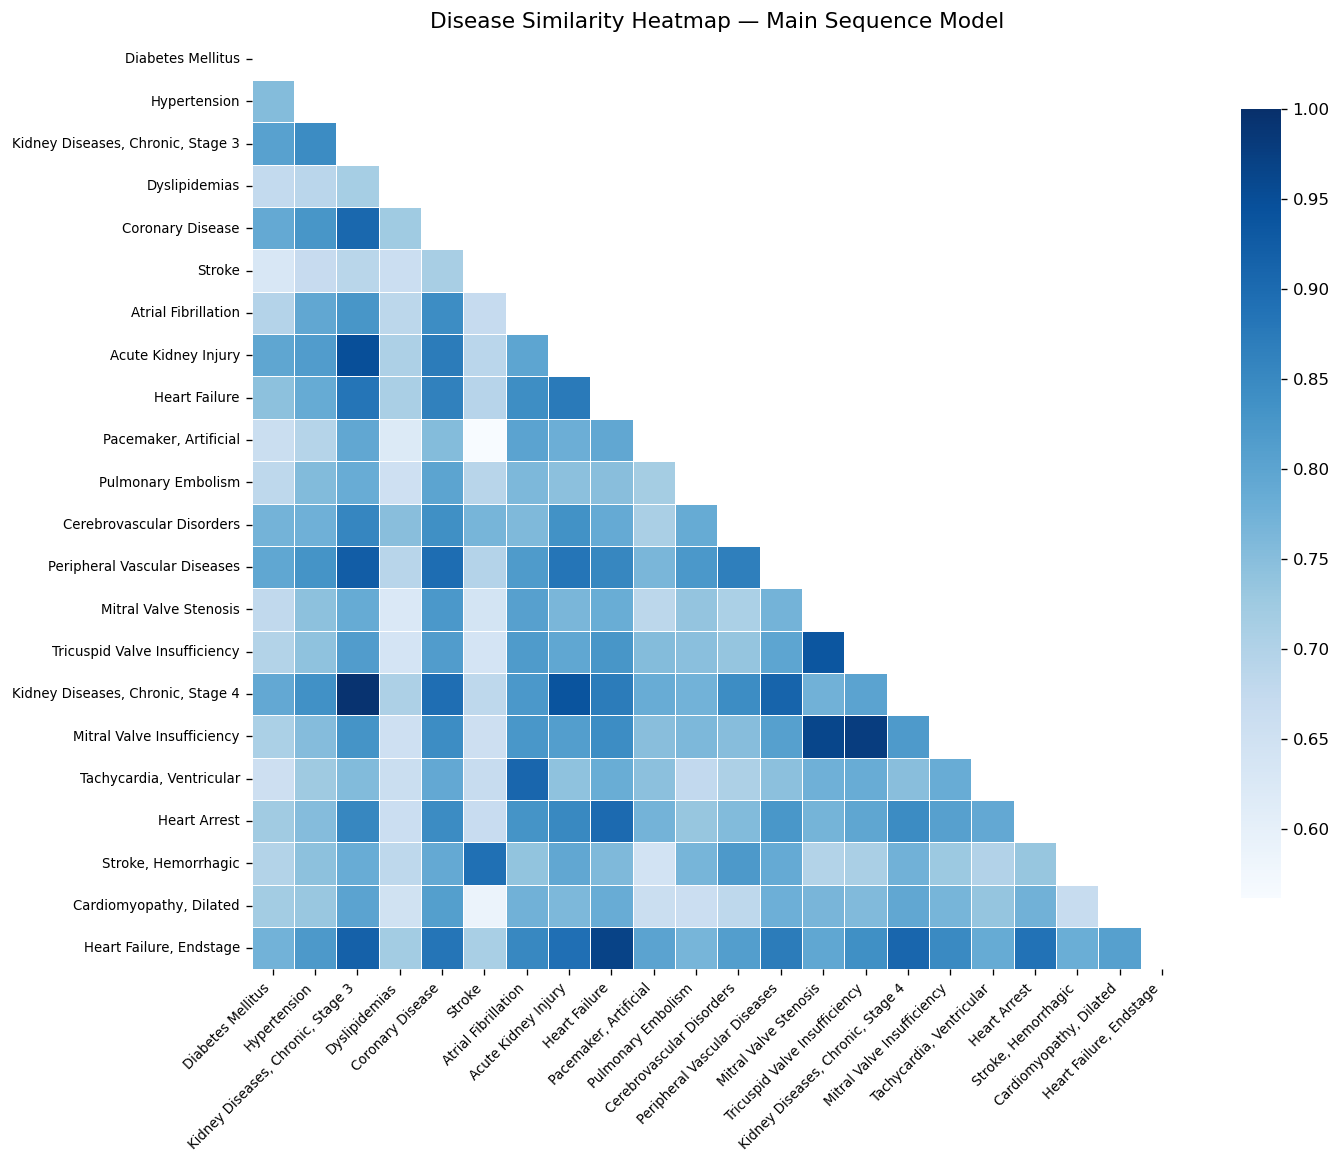

In [37]:
def plot_sim_heatmap(df: pd.DataFrame, title: str, fname: str,
                     vmin: float = None, vmax: float = None,
                     cmap: str = "Blues") -> None:
    """Lower-triangle seaborn heatmap for a square similarity matrix."""
    mask = np.triu(np.ones(df.shape, dtype=bool), k=0)
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(df, mask=mask, cmap=cmap, annot=False, square=True,
                linewidths=0.3, cbar_kws={"shrink": 0.8},
                vmin=vmin, vmax=vmax, ax=ax)
    ax.set_title(title, fontsize=13)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, fname), format="svg", bbox_inches="tight")
    plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, fname.replace(".svg", ".pdf")),
                bbox_inches="tight")
    plt.show()

plot_sim_heatmap(sim_main_df,
                 "Disease Similarity Heatmap — Main Sequence Model",
                 "disease_similarity_heatmap_main.svg",
                 vmin=VMIN_SIM, vmax=VMAX_SIM)


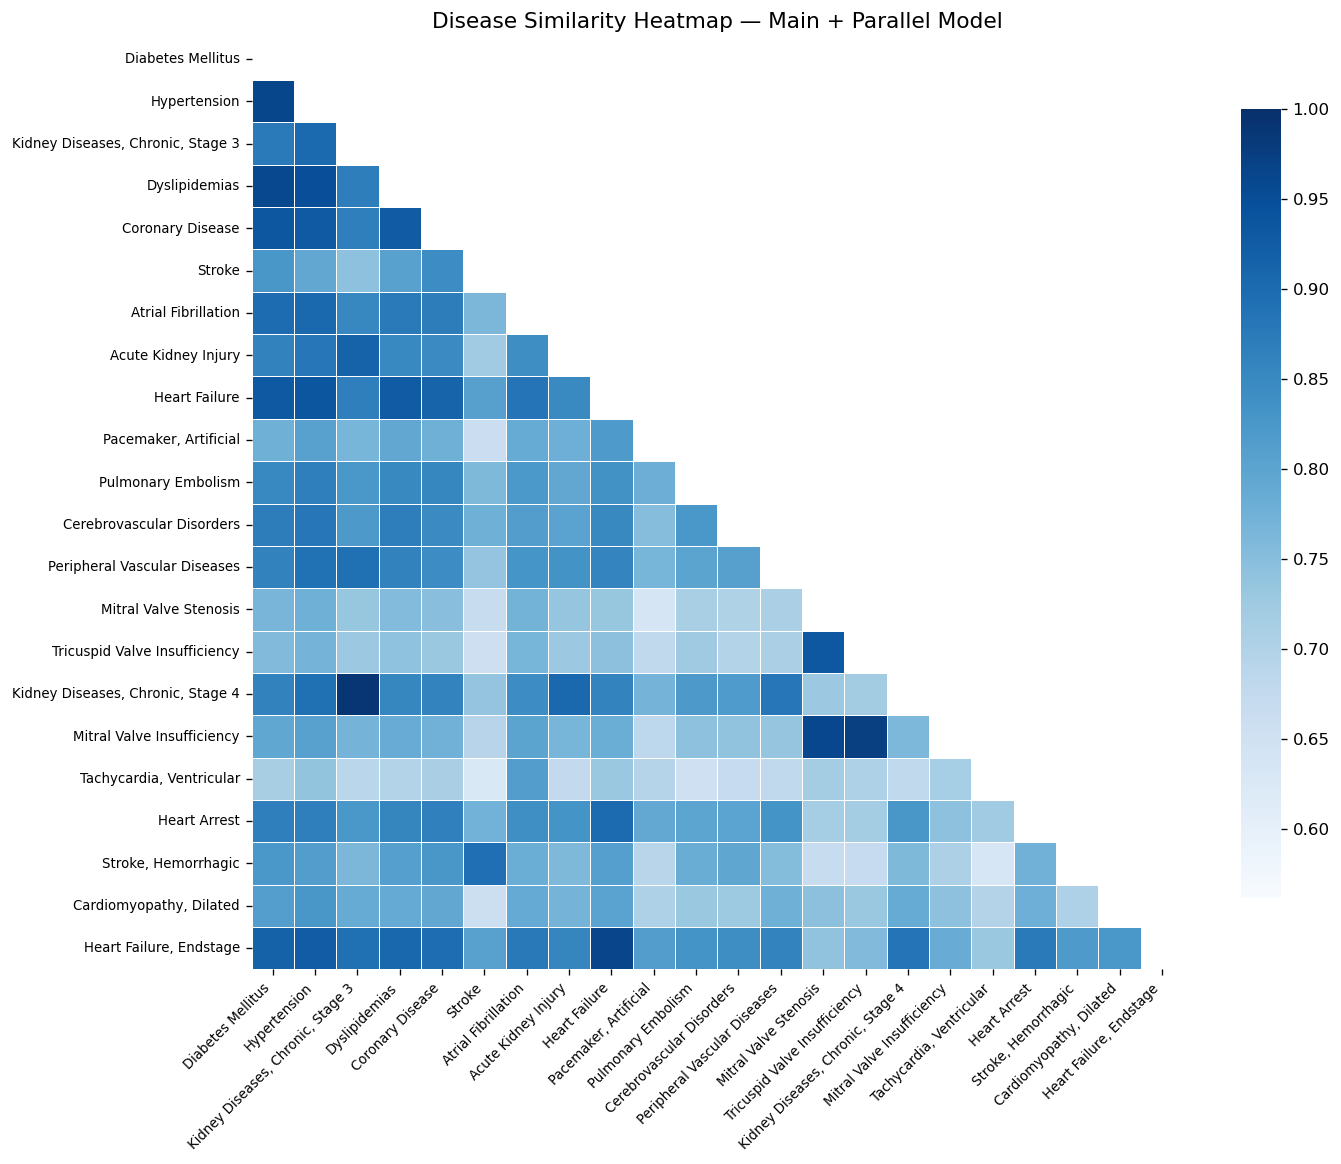

In [38]:
plot_sim_heatmap(sim_mainpar_24_df,
                 "Disease Similarity Heatmap — Main + Parallel Model",
                 "disease_similarity_heatmap_main_par.svg",
                 vmin=VMIN_SIM, vmax=VMAX_SIM)


  Network density: 0.4773


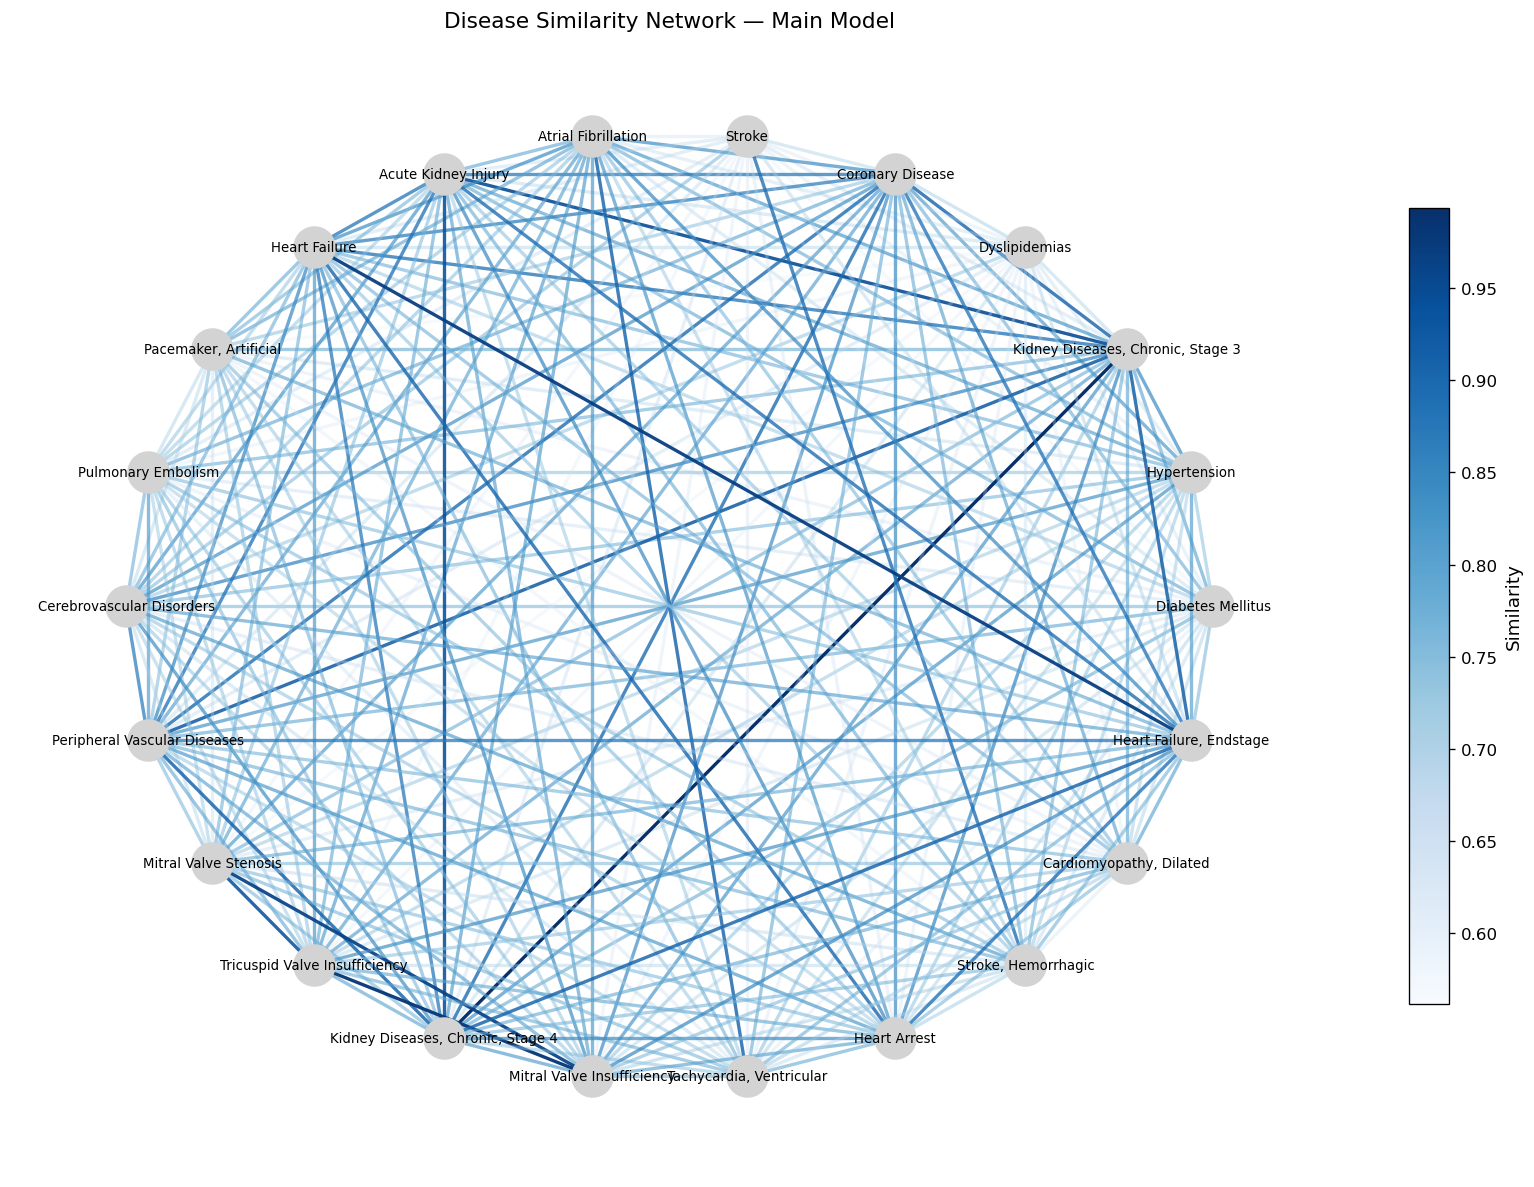

In [40]:
def weighted_graph_construction(correlation_df: pd.DataFrame,
                                  threshold: float = 0.0) -> nx.Graph:
    """Build undirected weighted NetworkX graph from a correlation/similarity DataFrame."""
    corr_arr   = np.abs(np.array(correlation_df))
    G          = nx.DiGraph()
    prot_names = list(correlation_df.columns)
    G.add_nodes_from(prot_names)
    n = corr_arr.shape[0]
    for i in range(n):
        for j in range(i + 1, n):
            if corr_arr[i, j] > threshold:
                G.add_edge(prot_names[i], prot_names[j], weight=corr_arr[i, j])
    print(f"  Network density: {len(G.edges()) / n**2:.4f}")
    return G.to_undirected()


def plot_weighted_graph_colored(G: nx.Graph, title: str = "",
                                 cmap_name: str = "coolwarm",
                                 layout: str = "circular",
                                 fname: str = None) -> None:
    """Plot weighted graph with edge colours proportional to weight."""
    fig, ax = plt.subplots(figsize=(14, 10))
    if layout == "spring":
        pos = nx.spring_layout(G, seed=1)
    elif layout == "kamada_kawai":
        pos = nx.kamada_kawai_layout(G)
    else:
        pos = nx.circular_layout(G)

    if G.number_of_edges() == 0:
        nx.draw_networkx(G, pos, ax=ax, node_color="lightgray",
                         node_size=600, font_size=9)
        ax.set_title(title or "Graph (no edges)")
        ax.axis("off")
        plt.tight_layout()
        plt.show()
        return

    weights  = [G[u][v].get("weight", 1.0) for u, v in G.edges()]
    min_w, max_w = min(weights), max(weights)
    cmap     = plt.colormaps[cmap_name]
    norm     = mcolors.Normalize(vmin=min_w if min_w < max_w else 0,
                                  vmax=max_w if min_w < max_w else 1)
    edge_colors = []
    for w in weights:
        base = cmap(norm(w))
        alpha = 0.1 + 0.9 * norm(w)
        edge_colors.append((*base[:3], alpha))

    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=600, node_color="lightgray")
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_color="black")
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors, width=2)

    sm = cm.ScalarMappable(norm=norm, cmap=cmap); sm.set_array([])
    plt.colorbar(sm, ax=ax, shrink=0.7).set_label("Similarity", fontsize=11)
    ax.set_title(title or "Graph Colored by Edge Similarity", fontsize=13)
    ax.axis("off")
    plt.tight_layout()
    if fname:
        plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, fname),
                    format="svg", bbox_inches="tight")
    plt.show()


# ── Network graph — main similarity ──────────────────────────────────────────
G_main = weighted_graph_construction(sim_main_df, threshold=0.0)
plot_weighted_graph_colored(G_main, title="Disease Similarity Network — Main Model",
                             cmap_name="Blues", layout="circular",
                             fname="graph_similarity_plot_main.svg")


  Network density: 0.4773


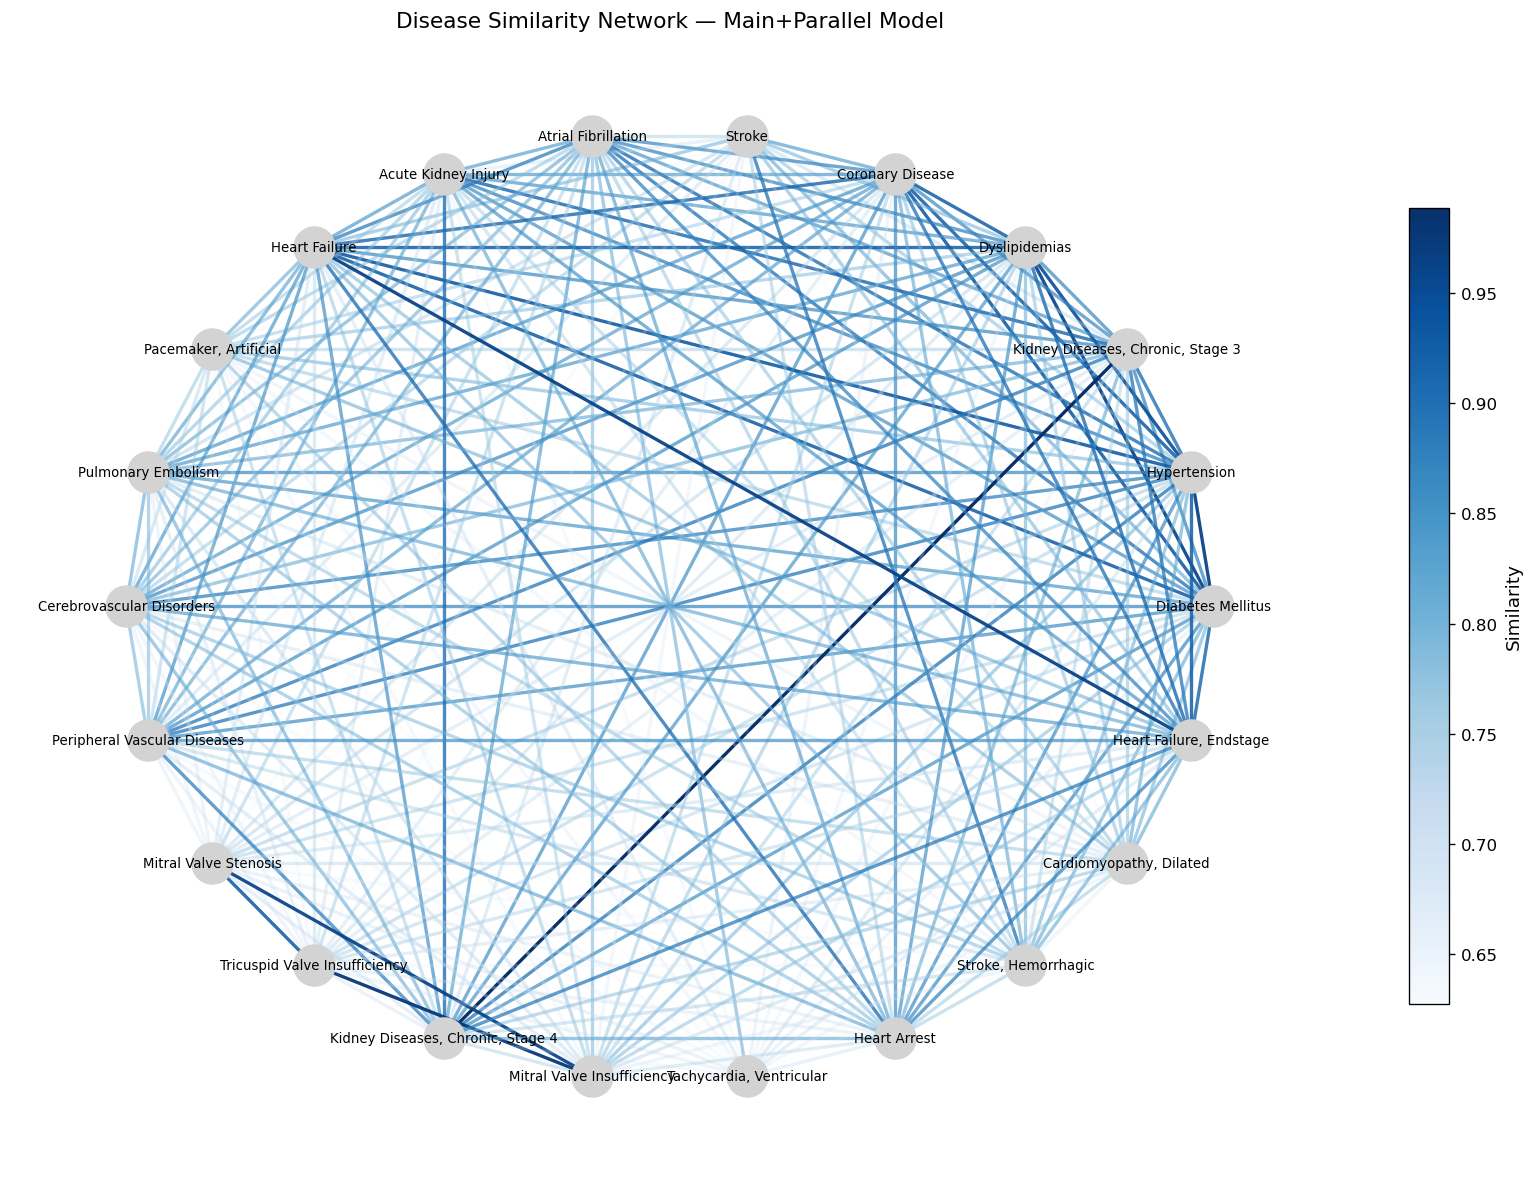

In [41]:
# ── Network graph — main+parallel similarity ──────────────────────────────────
G_mainpar = weighted_graph_construction(sim_mainpar_24_df, threshold=0.0)
plot_weighted_graph_colored(G_mainpar,
                             title="Disease Similarity Network — Main+Parallel Model",
                             cmap_name="Blues", layout="circular",
                             fname="graph_similarity_plot_main_par.svg")


## Section 4 — Comparison and Risk Factor Analysis

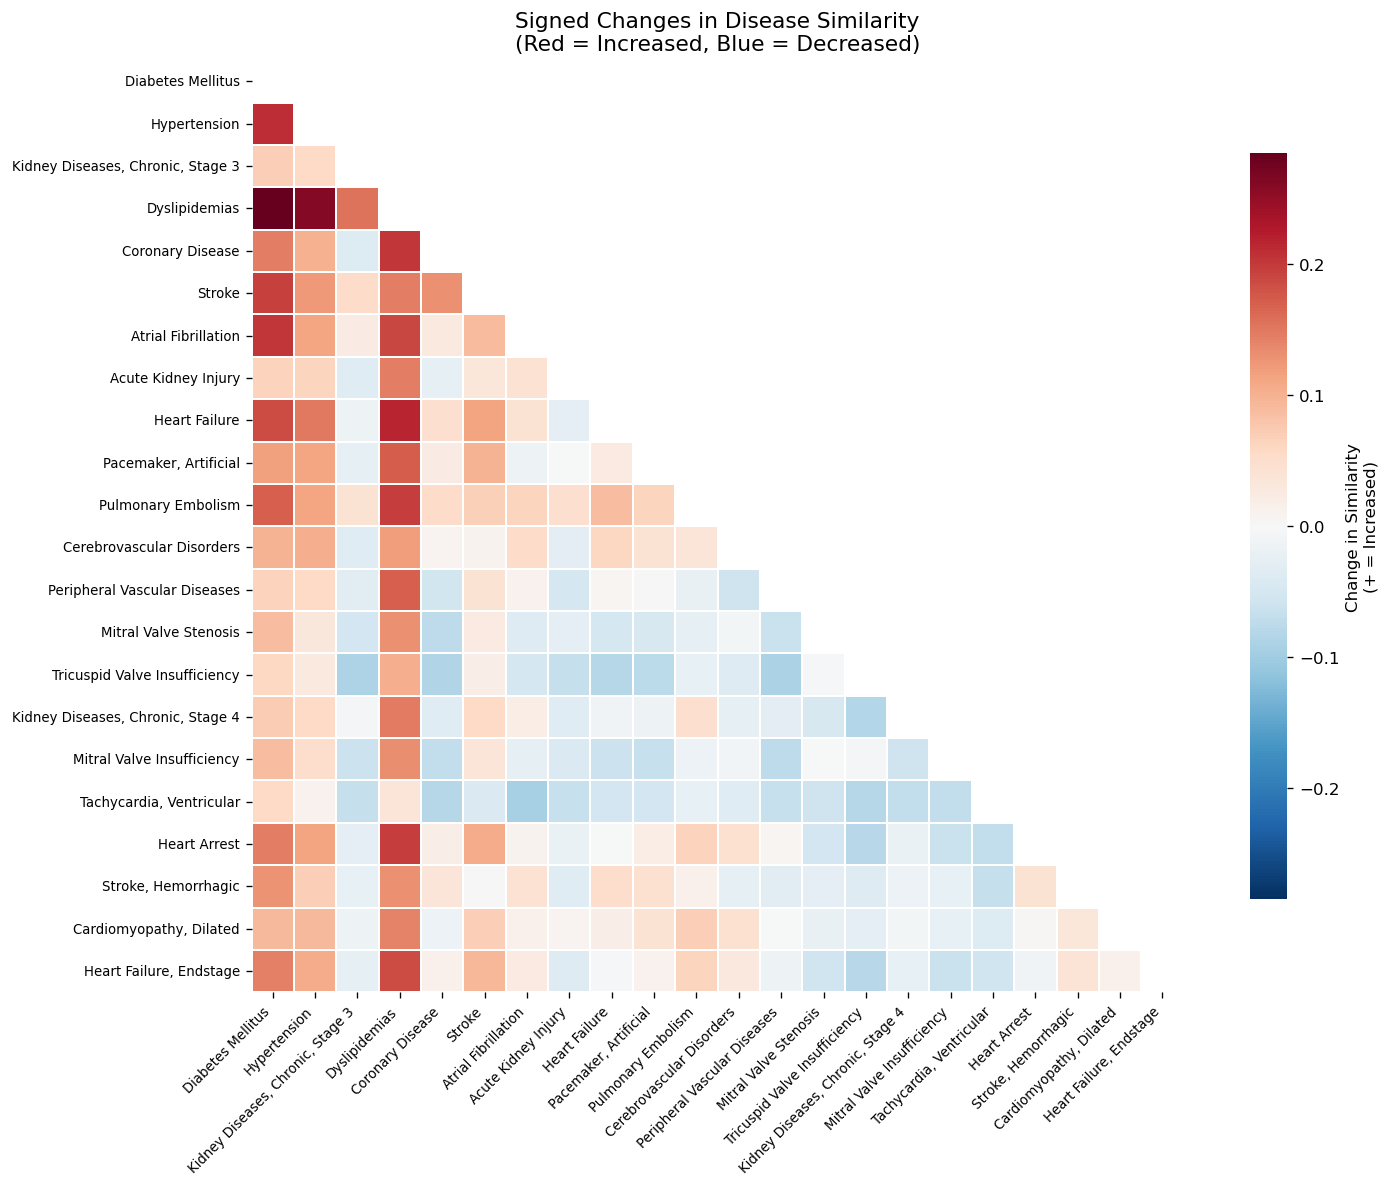

In [42]:
sim_diff_signed = sim_mainpar_24_df.subtract(sim_main_df)  # main_par - main
sim_diff_abs    = sim_diff_signed.abs()

mask_tri = np.triu(np.ones(sim_diff_signed.shape, dtype=bool), k=0)
fig, ax  = plt.subplots(figsize=(13, 10))
vmax_d   = float(np.nanmax(np.abs(sim_diff_signed.values)))
sns.heatmap(sim_diff_signed, mask=mask_tri, cmap="RdBu_r", center=0,
            vmin=-vmax_d, vmax=vmax_d, annot=False, square=True,
            linewidths=0.1, cbar_kws={"shrink": 0.8,
                                       "label": "Change in Similarity\n(+ = Increased)"},
            ax=ax)
ax.set_title("Signed Changes in Disease Similarity\n(Red = Increased, Blue = Decreased)",
             fontsize=13)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, "disease_similarity_changes_signed.svg"),
            format="svg", bbox_inches="tight")
plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, "disease_similarity_changes_signed.pdf"),
            bbox_inches="tight")
plt.show()


In [61]:
spearman_r, spearman_p = spearmanr(sim_main_df.values.flatten(), sim_mainpar_24_df.values.flatten())
spearman_r

0.5194797634741998

In [65]:
from scipy.stats import pearsonr, spearmanr, wilcoxon, ks_2samp
 
# Global network comparison metrics
diff_values = sim_diff_signed.values
mad = np.mean(np.abs(diff_values))
rmsd = np.sqrt(np.mean(diff_values**2))
max_change = np.max(np.abs(diff_values))
mean_change = np.mean(diff_values)
std_change = np.std(diff_values)

print(f"Mean Absolute Difference (MAD): {mad:.4f}")
print(f"Root Mean Square Difference (RMSD): {rmsd:.4f}")
print(f"Maximum Change: {max_change:.4f}")
print(f"Mean Change (directional): {mean_change:.4f}")
print(f"Standard Deviation of Changes: {std_change:.4f}")

# Percentage of relationships affected at different thresholds
thresh_001 = np.sum(np.abs(diff_values) > 0.01) / len(diff_values) * 100
thresh_005 = np.sum(np.abs(diff_values) > 0.05) / len(diff_values) * 100
thresh_010 = np.sum(np.abs(diff_values) > 0.10) / len(diff_values) * 100

print(f"\nPercentage of disease pairs affected:")
print(f"  >1% change: {thresh_001:.1f}%")
print(f"  >5% change: {thresh_005:.1f}%")
print(f"  >10% change: {thresh_010:.1f}%")

#Correlation analysis
spearman_r, spearman_p = spearmanr(sim_main_df.values.flatten(), sim_mainpar_24_df.values.flatten())
print(f"Spearman rank correlation: {spearman_r:.4f} (p={spearman_p:.2e})")

statistic, p_value = wilcoxon(diff_values.flatten(), alternative='two-sided')
print(f"Wilcoxon test for systematic change: p={p_value:.2e}")


Mean Absolute Difference (MAD): 0.0595
Root Mean Square Difference (RMSD): 0.0794
Maximum Change: 0.2844
Mean Change (directional): 0.0246
Standard Deviation of Changes: 0.0755

Percentage of disease pairs affected:
  >1% change: 1927.3%
  >5% change: 1045.5%
  >10% change: 381.8%
Spearman rank correlation: 0.5195 (p=8.38e-35)
Wilcoxon test for systematic change: p=3.04e-07


### 4.1  Confounding detection and validation

Adjust the `RF_CORRELATION_THRESHOLD` and `TOP_N_PAIRS` parameters below before running the fine-tuning cells.

> * `RF_CORRELATION_THRESHOLD`: minimum cosine similarity between a risk factor and a disease to consider the risk factor "highly correlated" with that disease.
>   **Default = median of the risk-factor × risk-factor similarity submatrix** (mirrors
>   the criterion used in the original analysis).
> * `TOP_N_PAIRS`: number of most-affected disease pairs to highlight in the analysis.
>   Sensitivity analysis below lets you explore multiple thresholds automatically.


In [45]:
# Risk-factor × risk-factor similarity submatrix 
sim_rf_rf = sim_all_df.loc[RF_NAMES, RF_NAMES].values

RF_CORRELATION_THRESHOLD = float(np.median(sim_rf_rf))  # override if desired
TOP_N_PAIRS              = 10   # number of top affected disease pairs

print(f"RF correlation threshold (median): {RF_CORRELATION_THRESHOLD:.4f}")
print(f"Top N pairs to analyse:            {TOP_N_PAIRS}")


RF correlation threshold (median): 0.8698
Top N pairs to analyse:            10


In [46]:
# Identify top affected disease pairs
upper_idx = np.triu_indices_from(sim_diff_signed.values, k=1)
pairs_list = []
for i, j in zip(*upper_idx):
    d1, d2 = DISEASE_NAMES_MAIN[i], DISEASE_NAMES_MAIN[j]
    change  = float(sim_diff_signed.iloc[i, j])
    pairs_list.append({"disease1": d1, "disease2": d2,
                        "change": change,
                        "abs_change": abs(change),
                        "direction": "increased" if change > 0 else "decreased"})

pairs_df = pd.DataFrame(pairs_list).sort_values("abs_change", ascending=False).reset_index(drop=True)
top_affected_pairs = pairs_df.head(TOP_N_PAIRS).to_dict("records")

print(f"Top {TOP_N_PAIRS} most affected disease pairs:")
display(pairs_df.head(TOP_N_PAIRS)[["disease1", "disease2", "change", "direction"]]
        .style.format({"change": "{:+.4f}"}))


Top 10 most affected disease pairs:


,disease1,disease2,change,direction
0,Diabetes Mellitus,Dyslipidemias,+0.2844,increased
1,Hypertension,Dyslipidemias,+0.2612,increased
2,Dyslipidemias,Heart Failure,+0.2168,increased
3,Diabetes Mellitus,Hypertension,+0.2104,increased
4,Dyslipidemias,Coronary Disease,+0.2026,increased
5,Diabetes Mellitus,Atrial Fibrillation,+0.2025,increased
6,Dyslipidemias,Heart Arrest,+0.1976,increased
7,Dyslipidemias,Pulmonary Embolism,+0.1973,increased
8,Diabetes Mellitus,Stroke,+0.1954,increased
9,Dyslipidemias,Atrial Fibrillation,+0.1890,increased


In [47]:
# Risk-factor correlation helper functions 
def find_correlated_risk_factors(disease_name: str,
                                  risk_factors: list,
                                  similarity_matrix: np.ndarray,
                                  all_phrases: list,
                                  threshold: float = 0.5,
                                  top_n: int = 10) -> list:
    """Find risk factors with cosine similarity ≥ threshold to a given disease."""
    if disease_name not in all_phrases:
        return []
    d_idx = all_phrases.index(disease_name)
    corrs = []
    for rf in risk_factors:
        if rf in all_phrases:
            rf_idx = all_phrases.index(rf)
            corr   = float(similarity_matrix[d_idx, rf_idx])
            if corr >= threshold:
                corrs.append({"risk_factor": rf, "correlation": corr})
    return sorted(corrs, key=lambda x: -x["correlation"])[:top_n]


def analyze_pair_shared_risk_factors(pair: dict,
                                      disease_correlations: dict) -> dict:
    """Compute shared high-correlated risk factors for a disease pair."""
    d1, d2 = pair["disease1"], pair["disease2"]
    rf1 = {c["risk_factor"] for c in disease_correlations.get(d1, [])}
    rf2 = {c["risk_factor"] for c in disease_correlations.get(d2, [])}
    shared = rf1 & rf2
    n_max  = max(len(rf1), len(rf2), 1)
    return {
        "pair":             f"{d1} ↔ {d2}",
        "change":           pair["change"],
        "n_rf_d1":          len(rf1),
        "n_rf_d2":          len(rf2),
        "n_shared":         len(shared),
        "normalized_shared": len(shared) / n_max,
    }


def analyze_disease_risk_correlations(diseases: list,
                                       risk_factors: list,
                                       all_phrases: list,
                                       similarity_matrix: np.ndarray,
                                       threshold: float = 0.5) -> dict:
    """Return {disease: [correlated risk factors]} for all diseases."""
    return {
        d: find_correlated_risk_factors(
            d, risk_factors, similarity_matrix, all_phrases, threshold
        )
        for d in diseases
    }


In [48]:
# Risk-factor analysis at the selected threshold 
disease_correlations = analyze_disease_risk_correlations(
    DISEASE_NAMES_MAIN, RF_NAMES, PHRASES_ALL,
    sim_all_arr, threshold=RF_CORRELATION_THRESHOLD
)

pair_analyses = [
    analyze_pair_shared_risk_factors(p, disease_correlations)
    for p in top_affected_pairs
]
df_pairs = pd.DataFrame(pair_analyses)
print("Shared risk-factor analysis for top affected pairs:")
display(df_pairs.style.format({
    "change": "{:+.4f}",
    "normalized_shared": "{:.3f}"
}))


Shared risk-factor analysis for top affected pairs:


,pair,change,n_rf_d1,n_rf_d2,n_shared,normalized_shared
0,Diabetes Mellitus ↔ Dyslipidemias,+0.2844,10,10,6,0.600
1,Hypertension ↔ Dyslipidemias,+0.2612,10,10,4,0.400
2,Dyslipidemias ↔ Heart Failure,+0.2168,10,10,7,0.700
3,Diabetes Mellitus ↔ Hypertension,+0.2104,10,10,8,0.800
4,Dyslipidemias ↔ Coronary Disease,+0.2026,10,10,3,0.300
5,Diabetes Mellitus ↔ Atrial Fibrillation,+0.2025,10,10,2,0.200
6,Dyslipidemias ↔ Heart Arrest,+0.1976,10,10,7,0.700
7,Dyslipidemias ↔ Pulmonary Embolism,+0.1973,10,10,3,0.300
8,Diabetes Mellitus ↔ Stroke,+0.1954,10,6,0,0.000
9,Dyslipidemias ↔ Atrial Fibrillation,+0.1890,10,10,3,0.300


### 4.2  Sensitivity analysis

Iterate over `RF_CORRELATION_THRESHOLD` values and track how the shared risk-factor results and the Mann-Whitney U test change.

> Adjust the `THRESHOLD_VALUES` to explore other values.

In [67]:
THRESHOLD_VALUES = [0.3, 0.5, 0.7, RF_CORRELATION_THRESHOLD, 0.9]   # add or remove values as needed

all_sensitivity_results = []

for t in THRESHOLD_VALUES:
    dc_t = analyze_disease_risk_correlations(
        DISEASE_NAMES_MAIN, RF_NAMES, PHRASES_ALL, sim_all_arr, threshold=t
    )
    pa_t = [analyze_pair_shared_risk_factors(p, dc_t) for p in top_affected_pairs]
    df_t = pd.DataFrame(pa_t)

    # Mann-Whitney U: top-N pairs vs remaining pairs
    rest_pairs = pairs_df.iloc[TOP_N_PAIRS:].to_dict("records")
    dc_rest    = analyze_disease_risk_correlations(
        DISEASE_NAMES_MAIN, RF_NAMES, PHRASES_ALL, sim_all_arr, threshold=t
    )
    pa_rest = [analyze_pair_shared_risk_factors(p, dc_rest) for p in rest_pairs]
    df_rest = pd.DataFrame(pa_rest) if pa_rest else pd.DataFrame(
        columns=df_t.columns)

    group_top  = df_t["normalized_shared"].dropna().values
    group_rest = df_rest["normalized_shared"].dropna().values if len(df_rest) > 0 else np.array([0.0])

    if len(group_top) > 0 and len(group_rest) > 0:
        stat, pval = mannwhitneyu(group_top, group_rest, alternative="greater")
    else:
        stat, pval = np.nan, np.nan

    all_sensitivity_results.append({
        "threshold":         t,
        "mw_pval":           pval,
        "mean_shared_top":   group_top.mean() if len(group_top) else np.nan,
        "mean_shared_rest":  group_rest.mean() if len(group_rest) else np.nan,
    })
    print(f"Threshold {t:.2f}: MWU p={pval:.4g} ")

df_sensitivity = pd.DataFrame(all_sensitivity_results)
print("\nSensitivity analysis summary:")
display(df_sensitivity.style.format({
    c: "{:.4f}" for c in df_sensitivity.select_dtypes(float).columns
}))


Threshold 0.30: MWU p=0.2932 
Threshold 0.50: MWU p=0.2932 
Threshold 0.70: MWU p=0.2932 
Threshold 0.87: MWU p=0.0002781 
Threshold 0.90: MWU p=8.856e-08 

Sensitivity analysis summary:


,threshold,mw_pval,mean_shared_top,mean_shared_rest
0,0.3000,0.2932,0.4300,0.3810
1,0.5000,0.2932,0.4300,0.3810
2,0.7000,0.2932,0.4300,0.3810
3,0.8698,0.0003,0.4300,0.1602
4,0.9000,0.0000,0.3600,0.0570


## Section 5 — Network Sparsification (Graphical Lasso / GGM)

We estimate a sparse inverse covariance (precision) matrix from the
event embedding matrix using cross-validated Graphical Lasso (scikit-learn).
The selected regularisation parameter `alpha_` is printed for transparency.

In [73]:
emb_df = pd.read_csv("phrase_embeddings_main_par_df.csv", index_col=0).T
print(f"Embedding matrix: {emb_df.shape}  (embedding_dim × phrases)")

# Standardise columns before fitting
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X = scaler.fit_transform(emb_df.values)

print("Fitting GraphicalLassoCV (cross-validated Graphical Lasso) …")
glasso = GraphicalLassoCV(cv=5, n_jobs=-1, max_iter=500)
glasso.fit(X)

precision_mat = glasso.precision_
print(f"  Selected alpha (lambda): {glasso.alpha_:.6f}")
print(f"  Precision matrix shape:  {precision_mat.shape}")

adj_GGM_df = pd.DataFrame(precision_mat,
                            index=emb_df.columns,
                            columns=emb_df.columns)
adj_GGM_df.to_csv(os.path.join(OUTPUT_GGM_DIR, "GGM_adj_main_par_full.csv"))
print(f"  Saved → {os.path.join(OUTPUT_GGM_DIR, 'GGM_adj_main_par_full.csv')}")


Embedding matrix: (200, 103)  (embedding_dim × phrases)
Fitting GraphicalLassoCV (cross-validated Graphical Lasso) …
  Selected alpha (lambda): 0.657624
  Precision matrix shape:  (103, 103)
  Saved → results_GGM/GGM_adj_main_par_full.csv


## Section 6 — GGM Network Visualisation

In [74]:
# Load GGM results
adj_GGM_df = pd.read_csv(
    os.path.join(OUTPUT_GGM_DIR, "GGM_adj_main_par_full.csv"), index_col=0
)

common_diseases = [d for d in DISEASE_NAMES_MAIN
                   if d in adj_GGM_df.index and d in adj_GGM_df.columns]
adj_GGM_df_main = adj_GGM_df.loc[common_diseases, common_diseases]
print(f"GGM matrix (diseases only): {adj_GGM_df_main.shape}")


GGM matrix (diseases only): (22, 22)


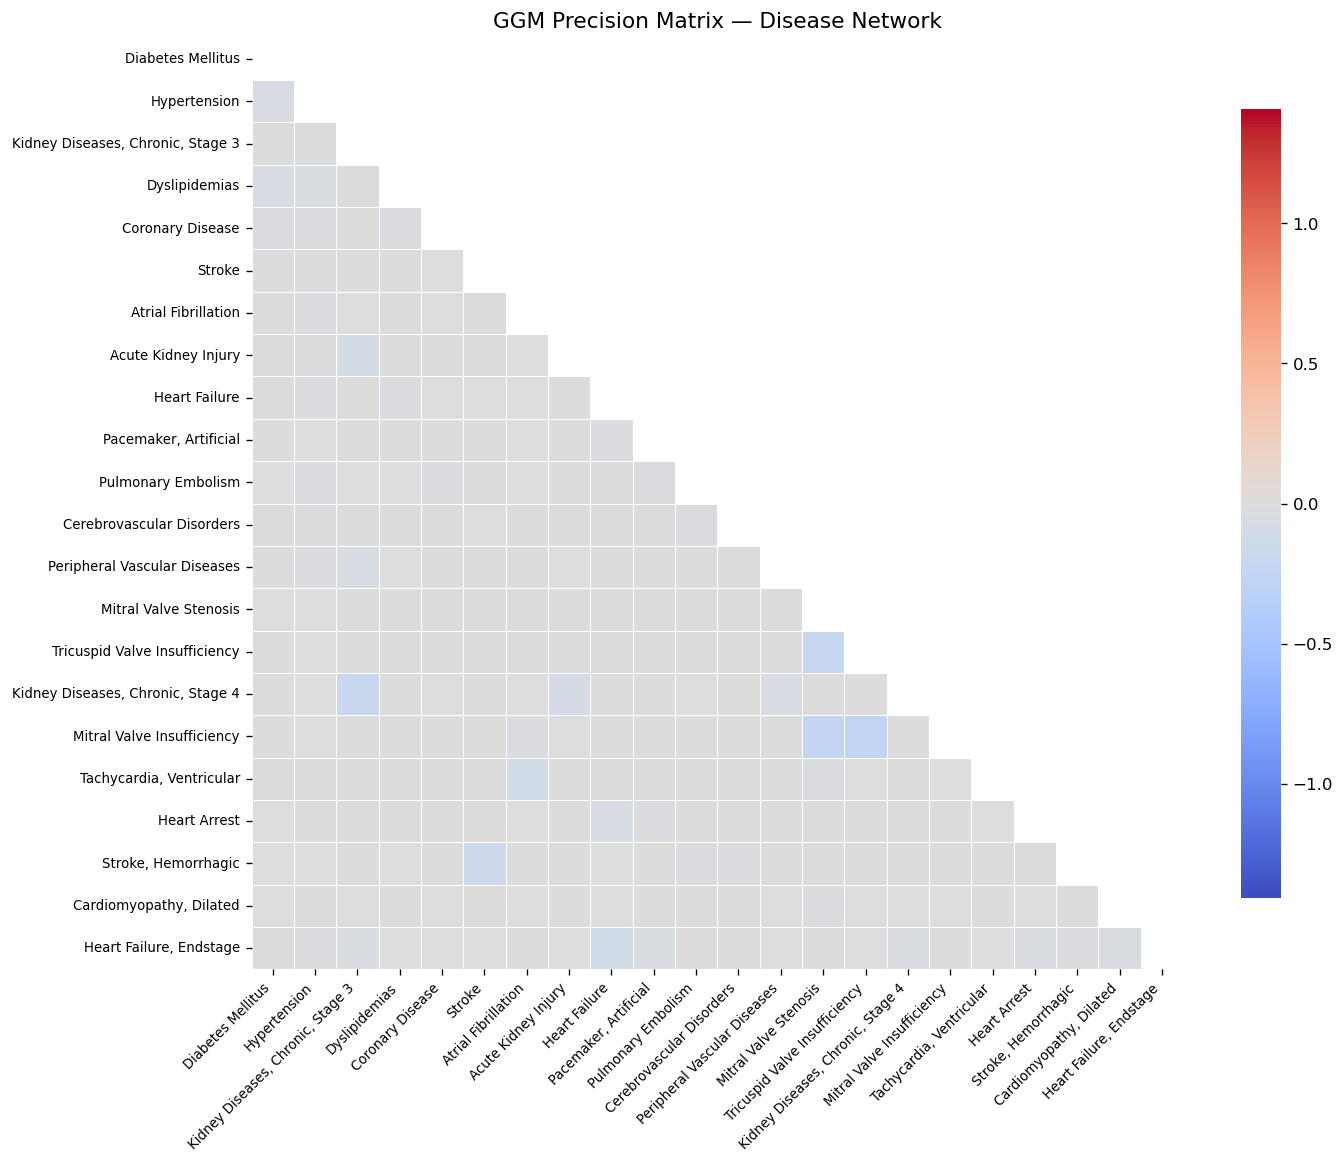

In [75]:
mask = np.triu(np.ones(adj_GGM_df_main.shape, dtype=bool), k=0)
vmax_g = float(np.nanmax(np.abs(adj_GGM_df_main.values)))

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(adj_GGM_df_main, mask=mask, cmap="coolwarm", center=0,
            vmin=-vmax_g, vmax=vmax_g, annot=False, square=True,
            linewidths=0.3, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("GGM Precision Matrix — Disease Network", fontsize=13)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, "disease_GGM_heatmap_main_par_weighted.svg"),
            format="svg", bbox_inches="tight")
plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, "disease_GGM_heatmap_main_par_weighted.pdf"),
            bbox_inches="tight")
plt.show()


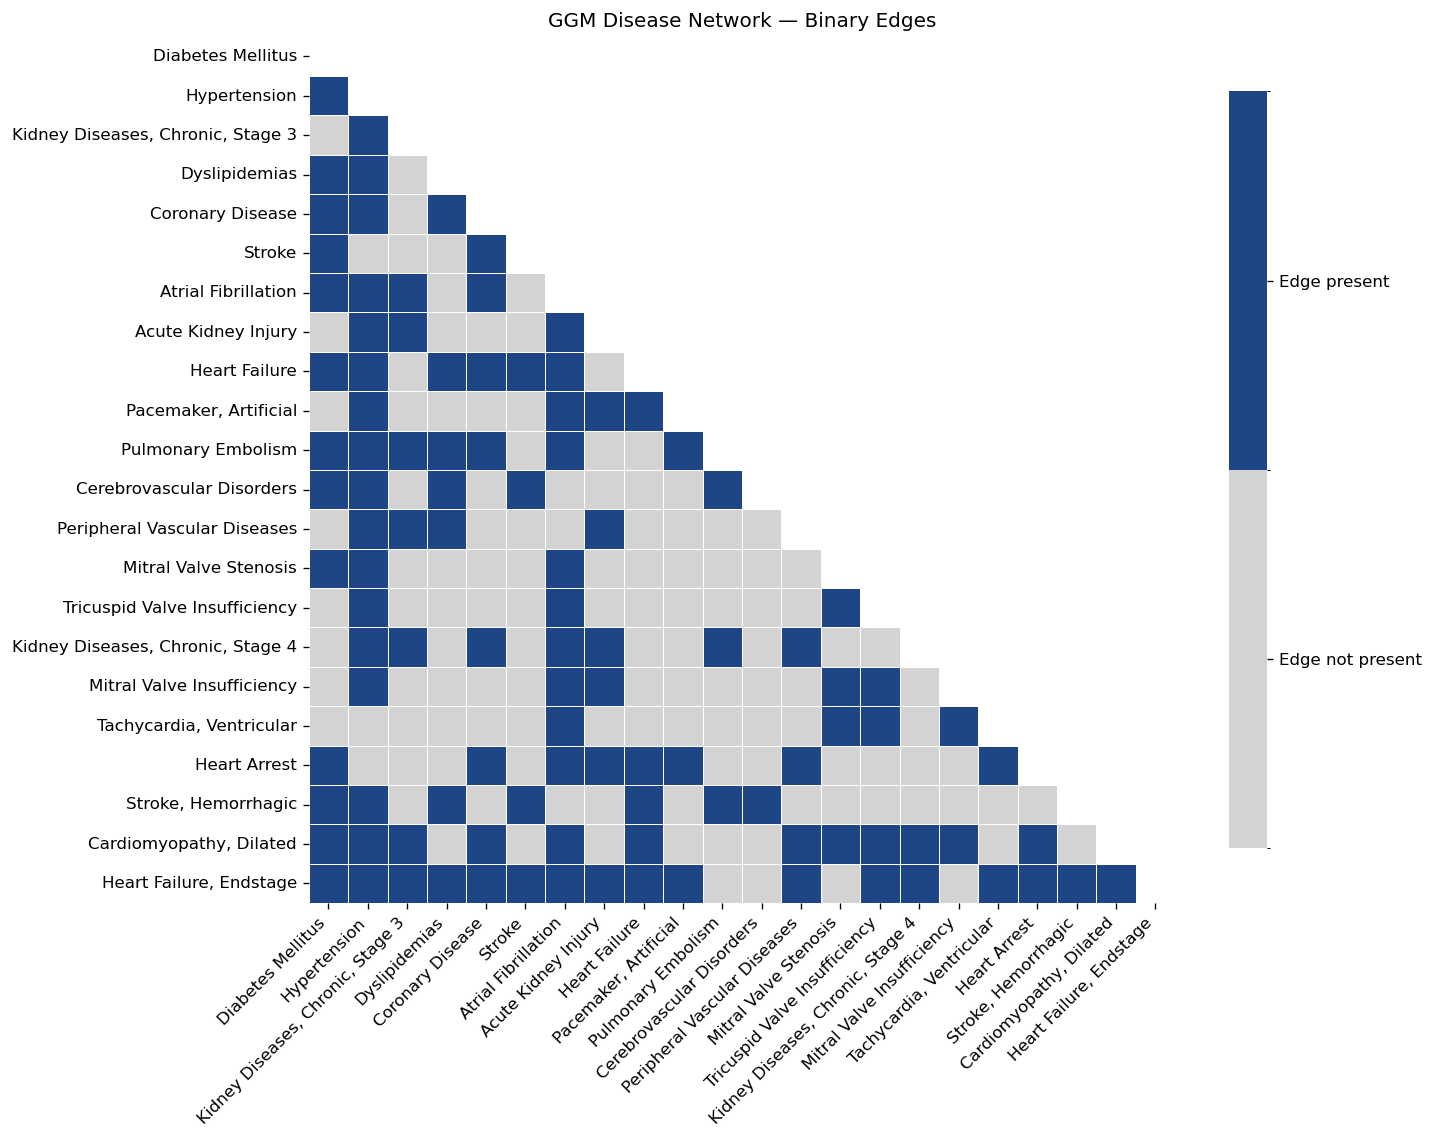

In [82]:
from matplotlib.colors import ListedColormap, BoundaryNorm
mask = np.triu(np.ones(adj_binary.shape, dtype=bool), k=0)
vals = adj_GGM_df_main.to_numpy()
adj_binary = np.where(vals == 0, 0, 1)
cmap = ListedColormap(["lightgray", "#1E4586"])
norm = BoundaryNorm([-0.5, 0.5, 1.5], cmap.N)


fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(adj_binary, mask=mask,
    cmap=cmap,
    norm=norm,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "ticks": [0, 1]}
)
 
# restore labels (since sign_mat is a numpy array)
ax.set_xticks(np.arange(adj_GGM_df_main.shape[1]) + 0.5)
ax.set_yticks(np.arange(adj_GGM_df_main.shape[0]) + 0.5)
ax.set_xticklabels(adj_GGM_df_main.columns, rotation=45, ha="right")
ax.set_yticklabels(adj_GGM_df_main.index, rotation=0)
 
cbar = ax.collections[0].colorbar
cbar.set_ticklabels(["Edge not present", "Edge present"])
 
plt.title("GGM Disease Network — Binary Edges")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, "disease_GGM_heatmap_main_par_binary.svg"),
            format="svg", bbox_inches="tight")
plt.show()


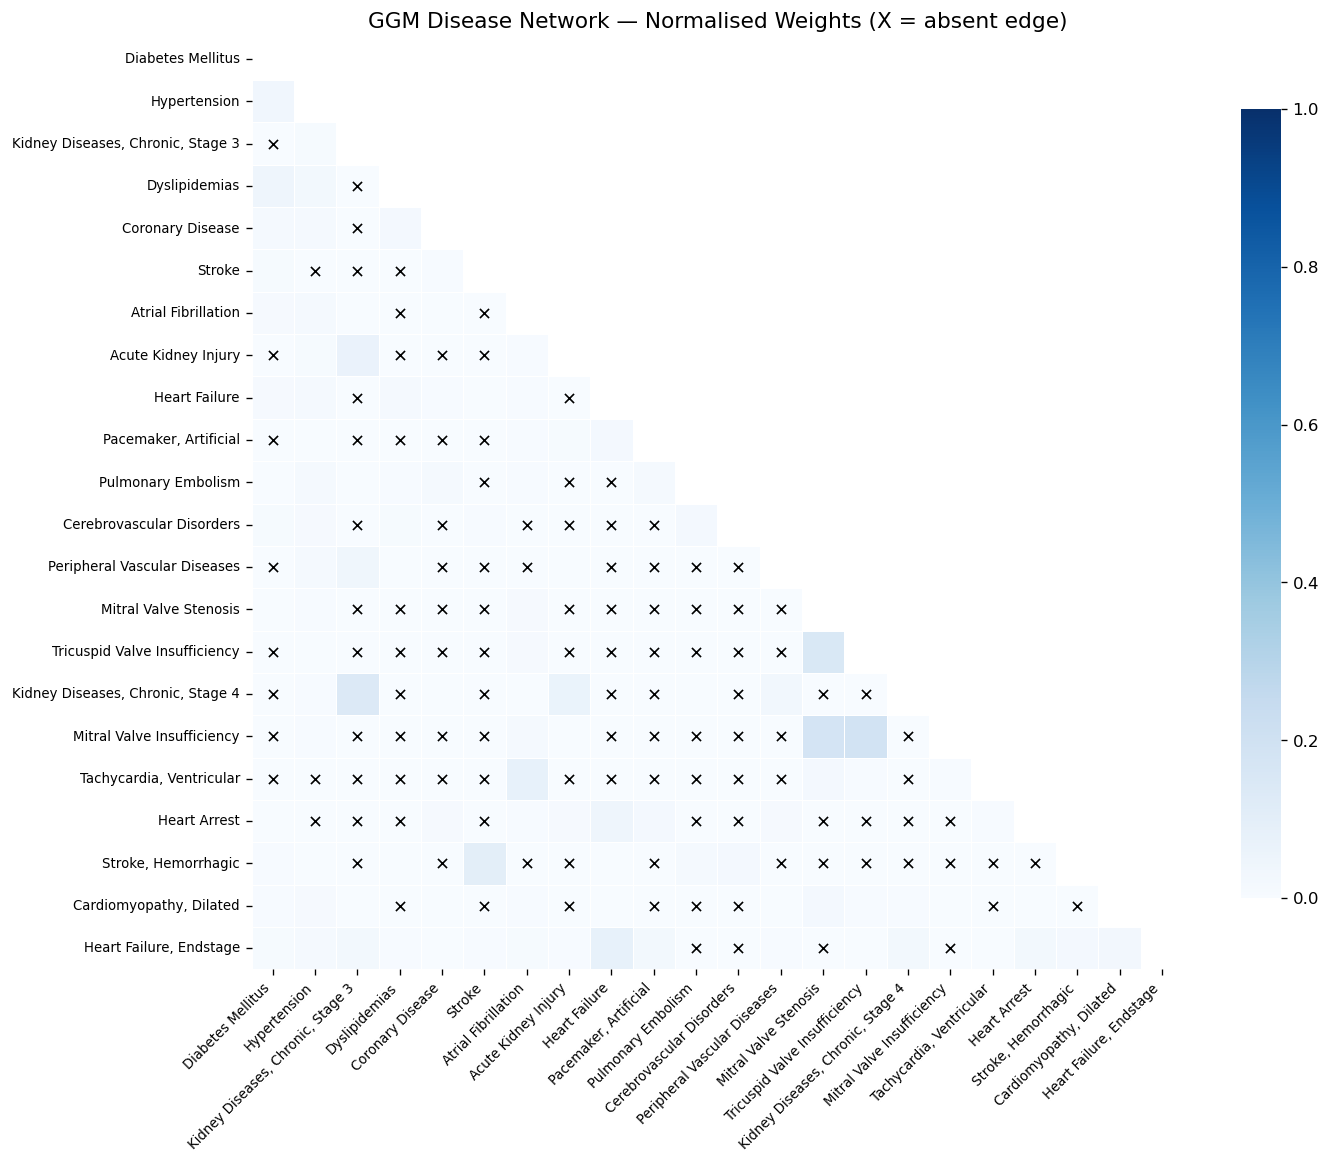

In [83]:
adj_GGM_abs = adj_GGM_df_main.abs()
_max_val = float(adj_GGM_abs.max().max())
adj_GGM_norm = adj_GGM_abs / _max_val if _max_val > 0 else adj_GGM_abs

mask = np.triu(np.ones(adj_GGM_norm.shape, dtype=bool), k=0)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(adj_GGM_norm, mask=mask, cmap="Blues", vmin=0, vmax=1,
            annot=False, square=True, linewidths=0.3,
            cbar_kws={"shrink": 0.8}, ax=ax)

# Mark zero-weight edges with an X
zero_mask  = (adj_GGM_df_main.values == 0)
lower_mask = np.tril(np.ones_like(zero_mask, bool), k=-1)
mark       = zero_mask & lower_mask
ys, xs     = np.where(mark)
ax.scatter(xs + 0.5, ys + 0.5, marker="x", s=30, linewidths=1.0, color="black")

ax.set_title("GGM Disease Network — Normalised Weights (X = absent edge)", fontsize=13)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, "disease_GGM_heatmap_main_par_weighted_normalized.svg"),
            format="svg", bbox_inches="tight")
plt.show()


  Network density: 0.2231


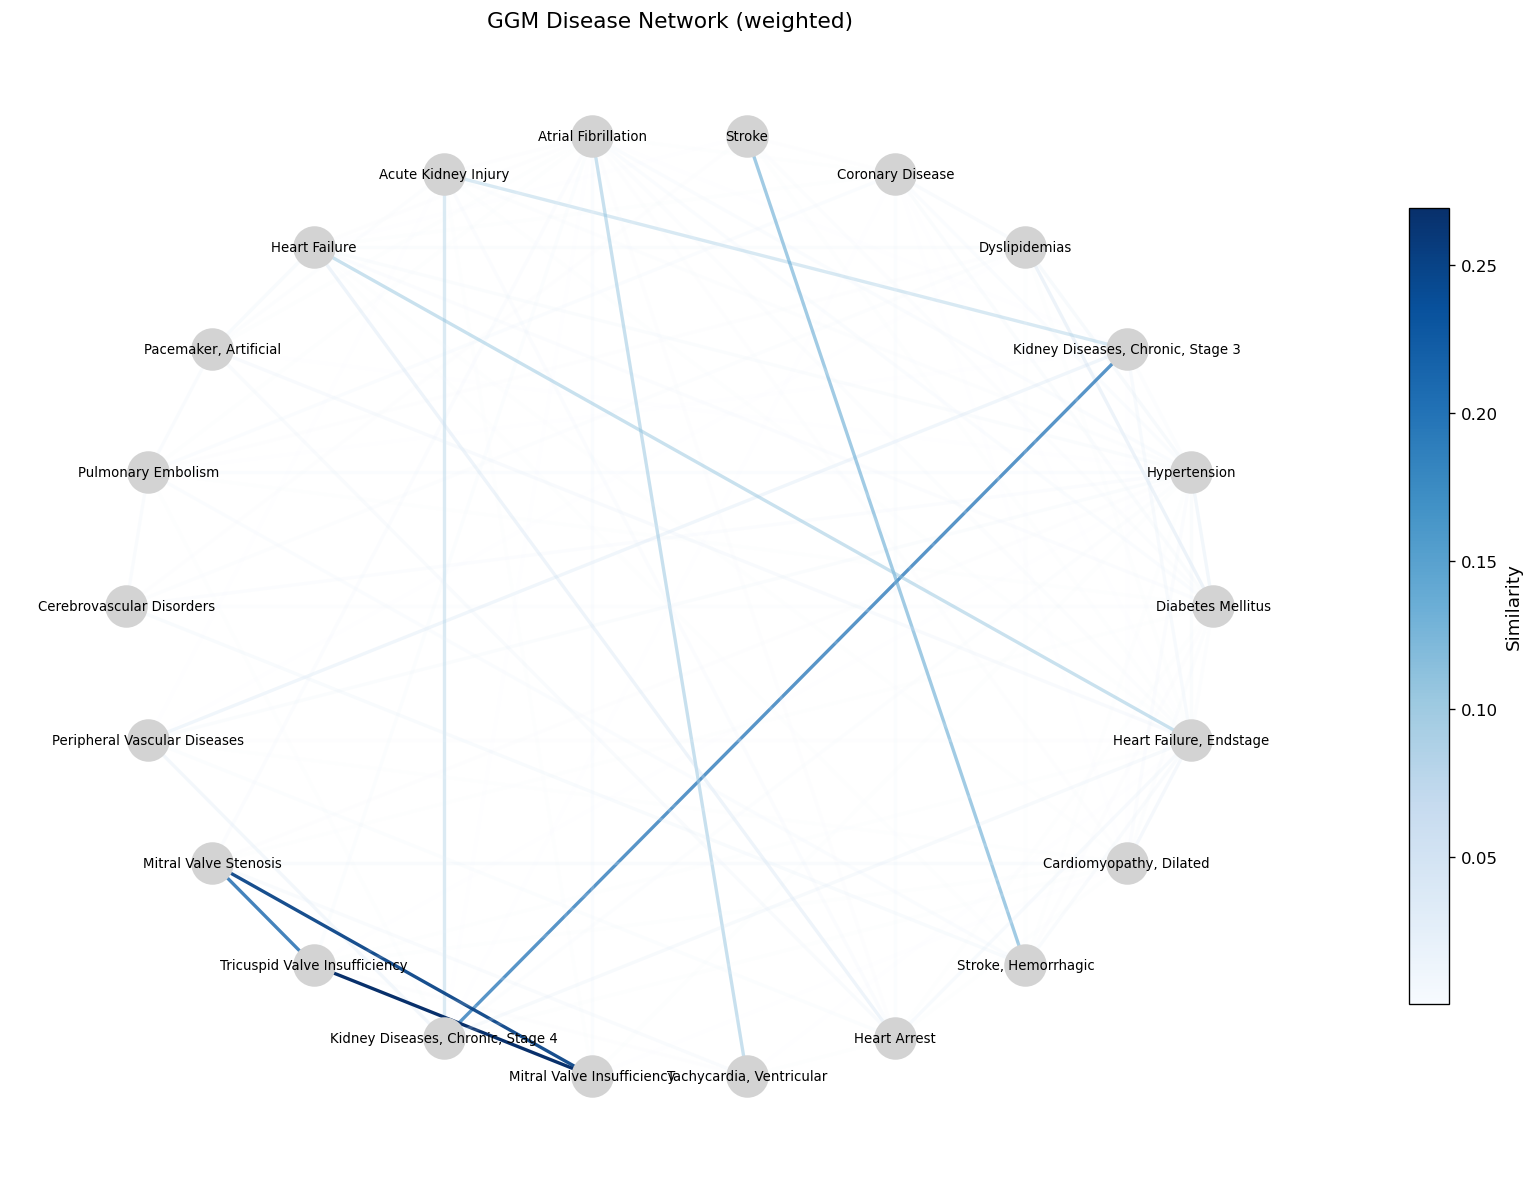

In [86]:
G_ggm = weighted_graph_construction(adj_GGM_df_main, threshold=0.0)
plot_weighted_graph_colored(G_ggm,
                             title="GGM Disease Network (weighted)",
                             cmap_name="Blues", layout="circular",
                             fname="graph_GGM_plot_main_weighted.svg")


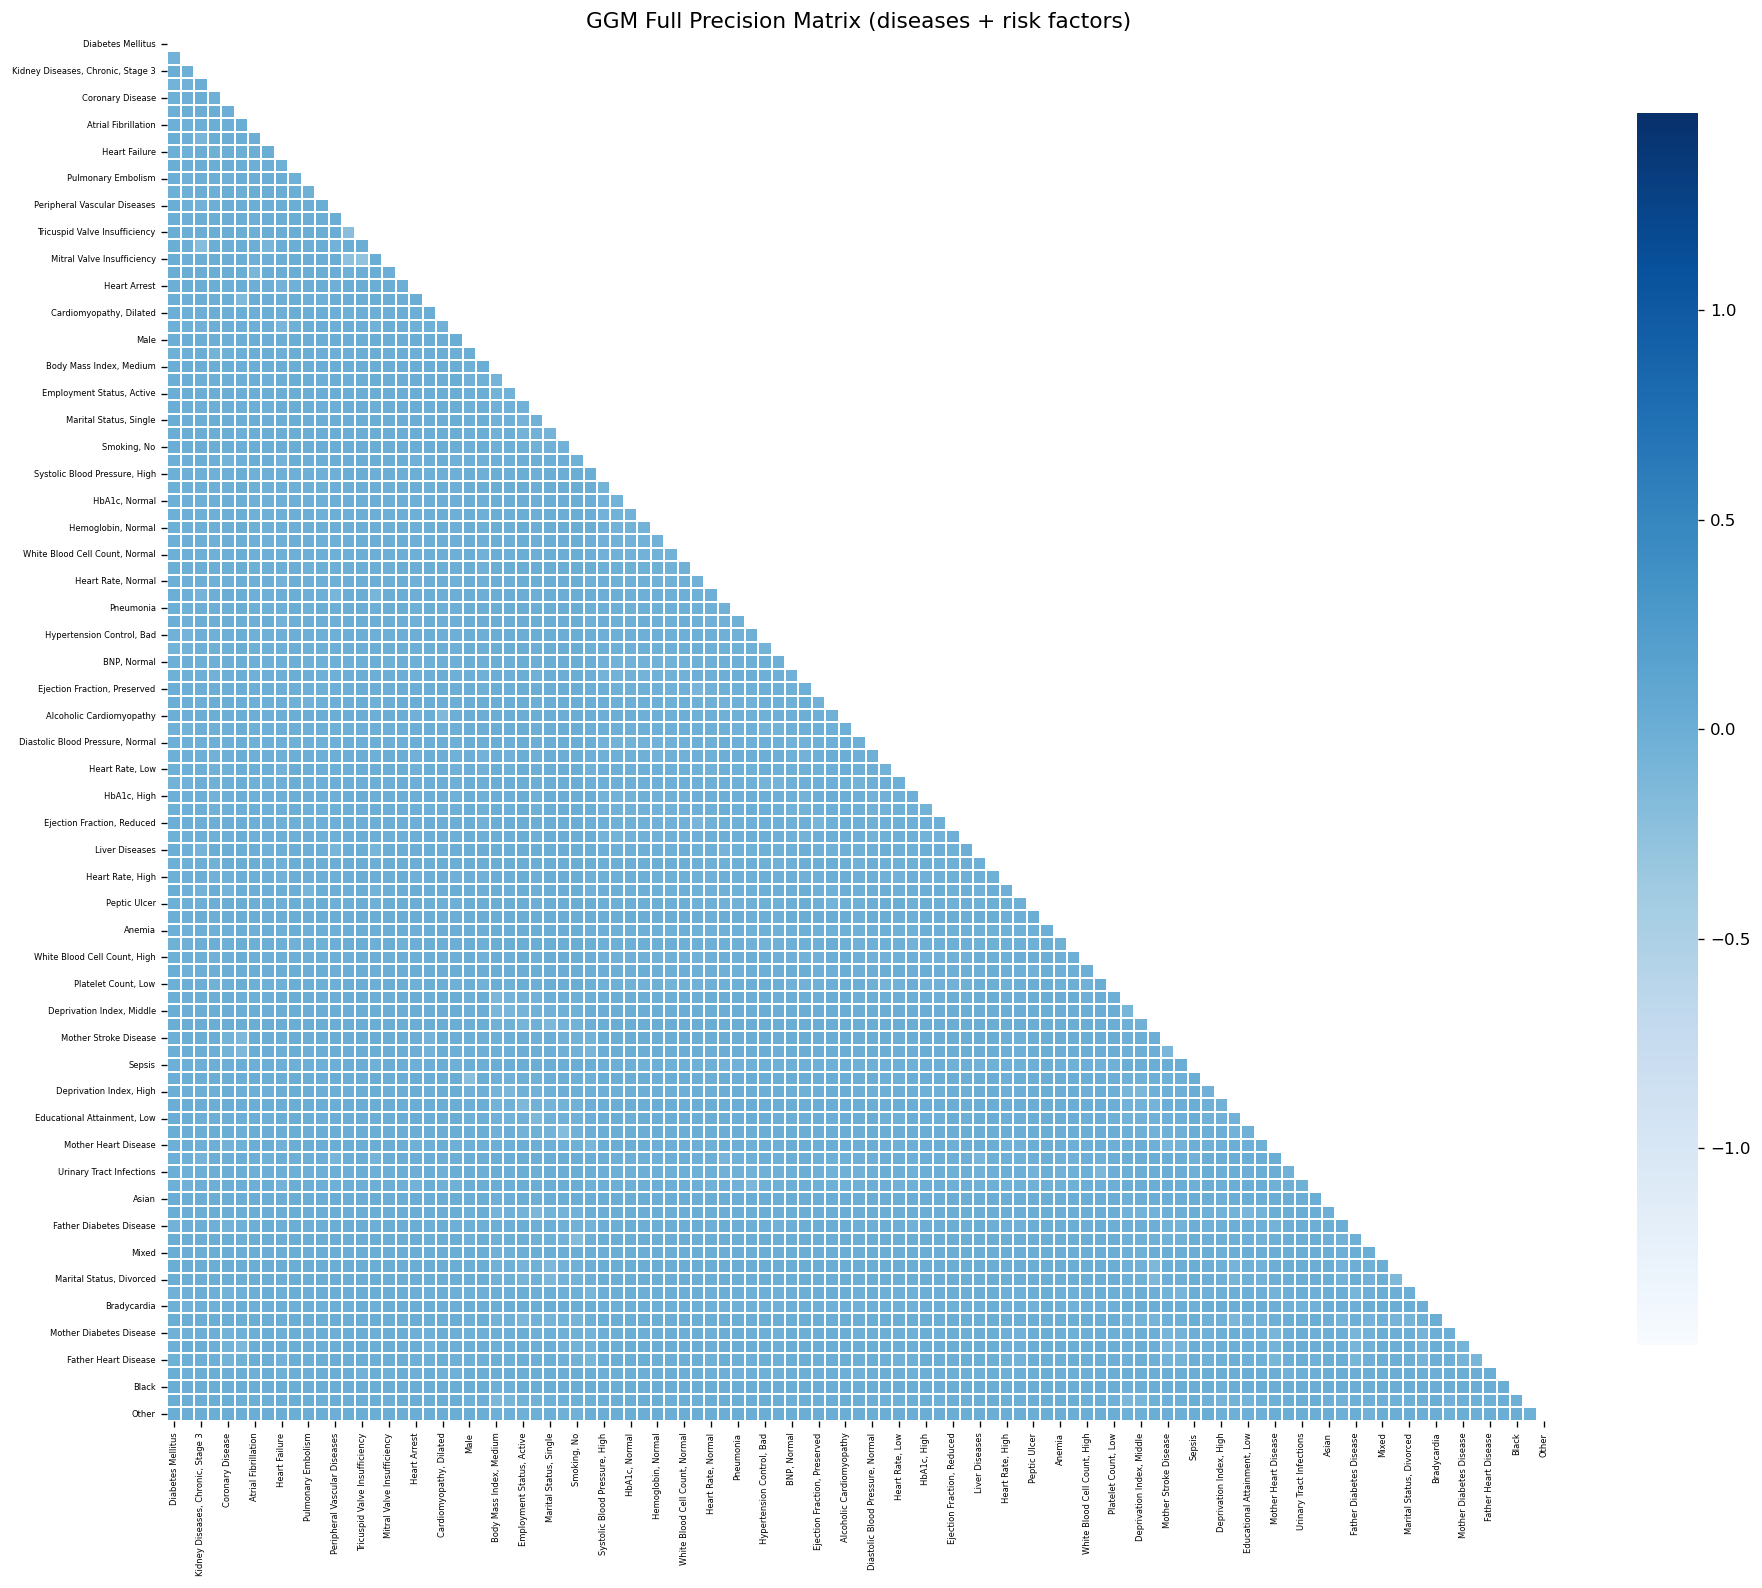

In [88]:
mask = np.triu(np.ones(adj_GGM_df.shape, dtype=bool), k=0)
vmax_full = float(np.nanmax(np.abs(adj_GGM_df.values)))

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(adj_GGM_df, mask=mask, cmap="Blues", center=0,
            vmin=-vmax_full, vmax=vmax_full, annot=False, square=True,
            linewidths=0.1, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("GGM Full Precision Matrix (diseases + risk factors)", fontsize=13)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=5)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=5)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, "disease_GGM_heatmap_main_par_full_weighted.svg"),
            format="svg", bbox_inches="tight")
plt.show()


## Section 7 — Topological Analysis and Community Detection

In [89]:
from networkx.algorithms.community import (
    greedy_modularity_communities,
    girvan_newman,
)

# Build NetworkX graph from GGM adjacency (absolute values, no self-loops)
adj_abs = adj_GGM_df_main.abs()
G_topo  = nx.from_pandas_adjacency(adj_abs)
G_topo.remove_edges_from(list(nx.selfloop_edges(G_topo)))

# Remove zero-weight edges
G_topo = nx.Graph([
    (u, v, d) for u, v, d in G_topo.edges(data=True) if d.get("weight", 0) > 0
])
print(f"Network:  {G_topo.number_of_nodes()} nodes  |  {G_topo.number_of_edges()} edges")


Network:  22 nodes  |  108 edges


In [90]:
edge_density = nx.density(G_topo)
try:
    diameter = nx.diameter(G_topo)
except nx.NetworkXError:
    diameter = "disconnected"

net_stats = pd.DataFrame({
    "Metric": ["Nodes", "Edges", "Edge Density", "Diameter"],
    "Value":  [G_topo.number_of_nodes(), G_topo.number_of_edges(),
               round(edge_density, 4), diameter],
})
print("Basic network statistics:")
display(net_stats.set_index("Metric"))


Basic network statistics:


,Value
Metric,
Nodes,22.0000
Edges,108.0000
Edge Density,0.4675
Diameter,3.0000


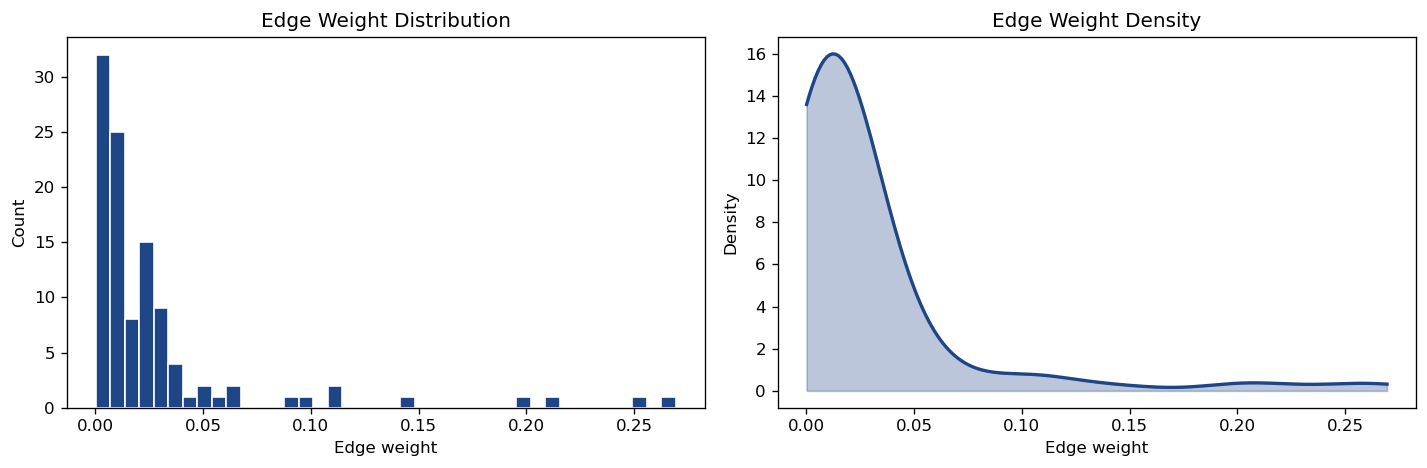

In [91]:
edge_weights = [d["weight"] for _, _, d in G_topo.edges(data=True)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(edge_weights, bins=40, color="#1E4586", edgecolor="white")
axes[0].set_xlabel("Edge weight"); axes[0].set_ylabel("Count")
axes[0].set_title("Edge Weight Distribution")

from scipy.stats import gaussian_kde
kde = gaussian_kde(edge_weights)
xs  = np.linspace(min(edge_weights), max(edge_weights), 200)
axes[1].plot(xs, kde(xs), color="#1E4586", linewidth=2)
axes[1].fill_between(xs, kde(xs), alpha=0.3, color="#1E4586")
axes[1].set_xlabel("Edge weight"); axes[1].set_ylabel("Density")
axes[1].set_title("Edge Weight Density")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, "edge_weight_distribution.svg"),
            format="svg", bbox_inches="tight")
plt.show()


In [93]:
# Community detection 
cfg_communities = list(greedy_modularity_communities(G_topo, weight=None))
cfg_map         = {}
for comm_id, comm in enumerate(cfg_communities):
    for node in comm:
        cfg_map[node] = comm_id
print(f"Fast Greedy: {len(cfg_communities)} communities")

Fast Greedy: 3 communities


In [94]:
degree_cent     = nx.degree_centrality(G_topo)
betweenness_cent = nx.betweenness_centrality(G_topo, weight=None)

topology_df = pd.DataFrame({
    "Node":                [n for n in G_topo.nodes()],
    "cfg_community":       [cfg_map.get(n, -1) for n in G_topo.nodes()],
    "centrality_degree":   [G_topo.degree(n) for n in G_topo.nodes()],
    "betweenness":         [betweenness_cent[n] for n in G_topo.nodes()],
})
topology_df["centrality_degree_rank"] = (
    topology_df["centrality_degree"].rank(ascending=False, method="min").astype(int)
)
topology_df["centrality_betweenness_rank"] = (
    topology_df["betweenness"].rank(ascending=False, method="min").astype(int)
)
topology_df = topology_df.sort_values("centrality_degree_rank").reset_index(drop=True)

out_csv = os.path.join(OUTPUT_BASE_DIR, "Node_Community_detection_centrality.csv")
topology_df.to_csv(out_csv, index=False)
print(f"Saved: {out_csv}")
display(topology_df.style.format({"betweenness": "{:.4f}"}))


Saved: Baseline/Node_Community_detection_centrality.csv


,Node,cfg_community,centrality_degree,betweenness,centrality_degree_rank,centrality_betweenness_rank
0,Hypertension,0,18,0.1345,1,1
1,"Heart Failure, Endstage",1,17,0.1186,2,2
2,Atrial Fibrillation,2,16,0.0777,3,3
3,Diabetes Mellitus,0,13,0.0490,4,4
4,"Cardiomyopathy, Dilated",2,13,0.0401,4,5
5,Coronary Disease,0,11,0.0193,6,9
6,Heart Failure,0,11,0.0207,6,8
7,Heart Arrest,1,10,0.0215,8,7
8,Pulmonary Embolism,0,10,0.0262,8,6
9,Dyslipidemias,0,9,0.0130,10,11


### 7.1  Community-coloured network visualisation

Nodes are coloured by community (Fast Greedy assignment by default).

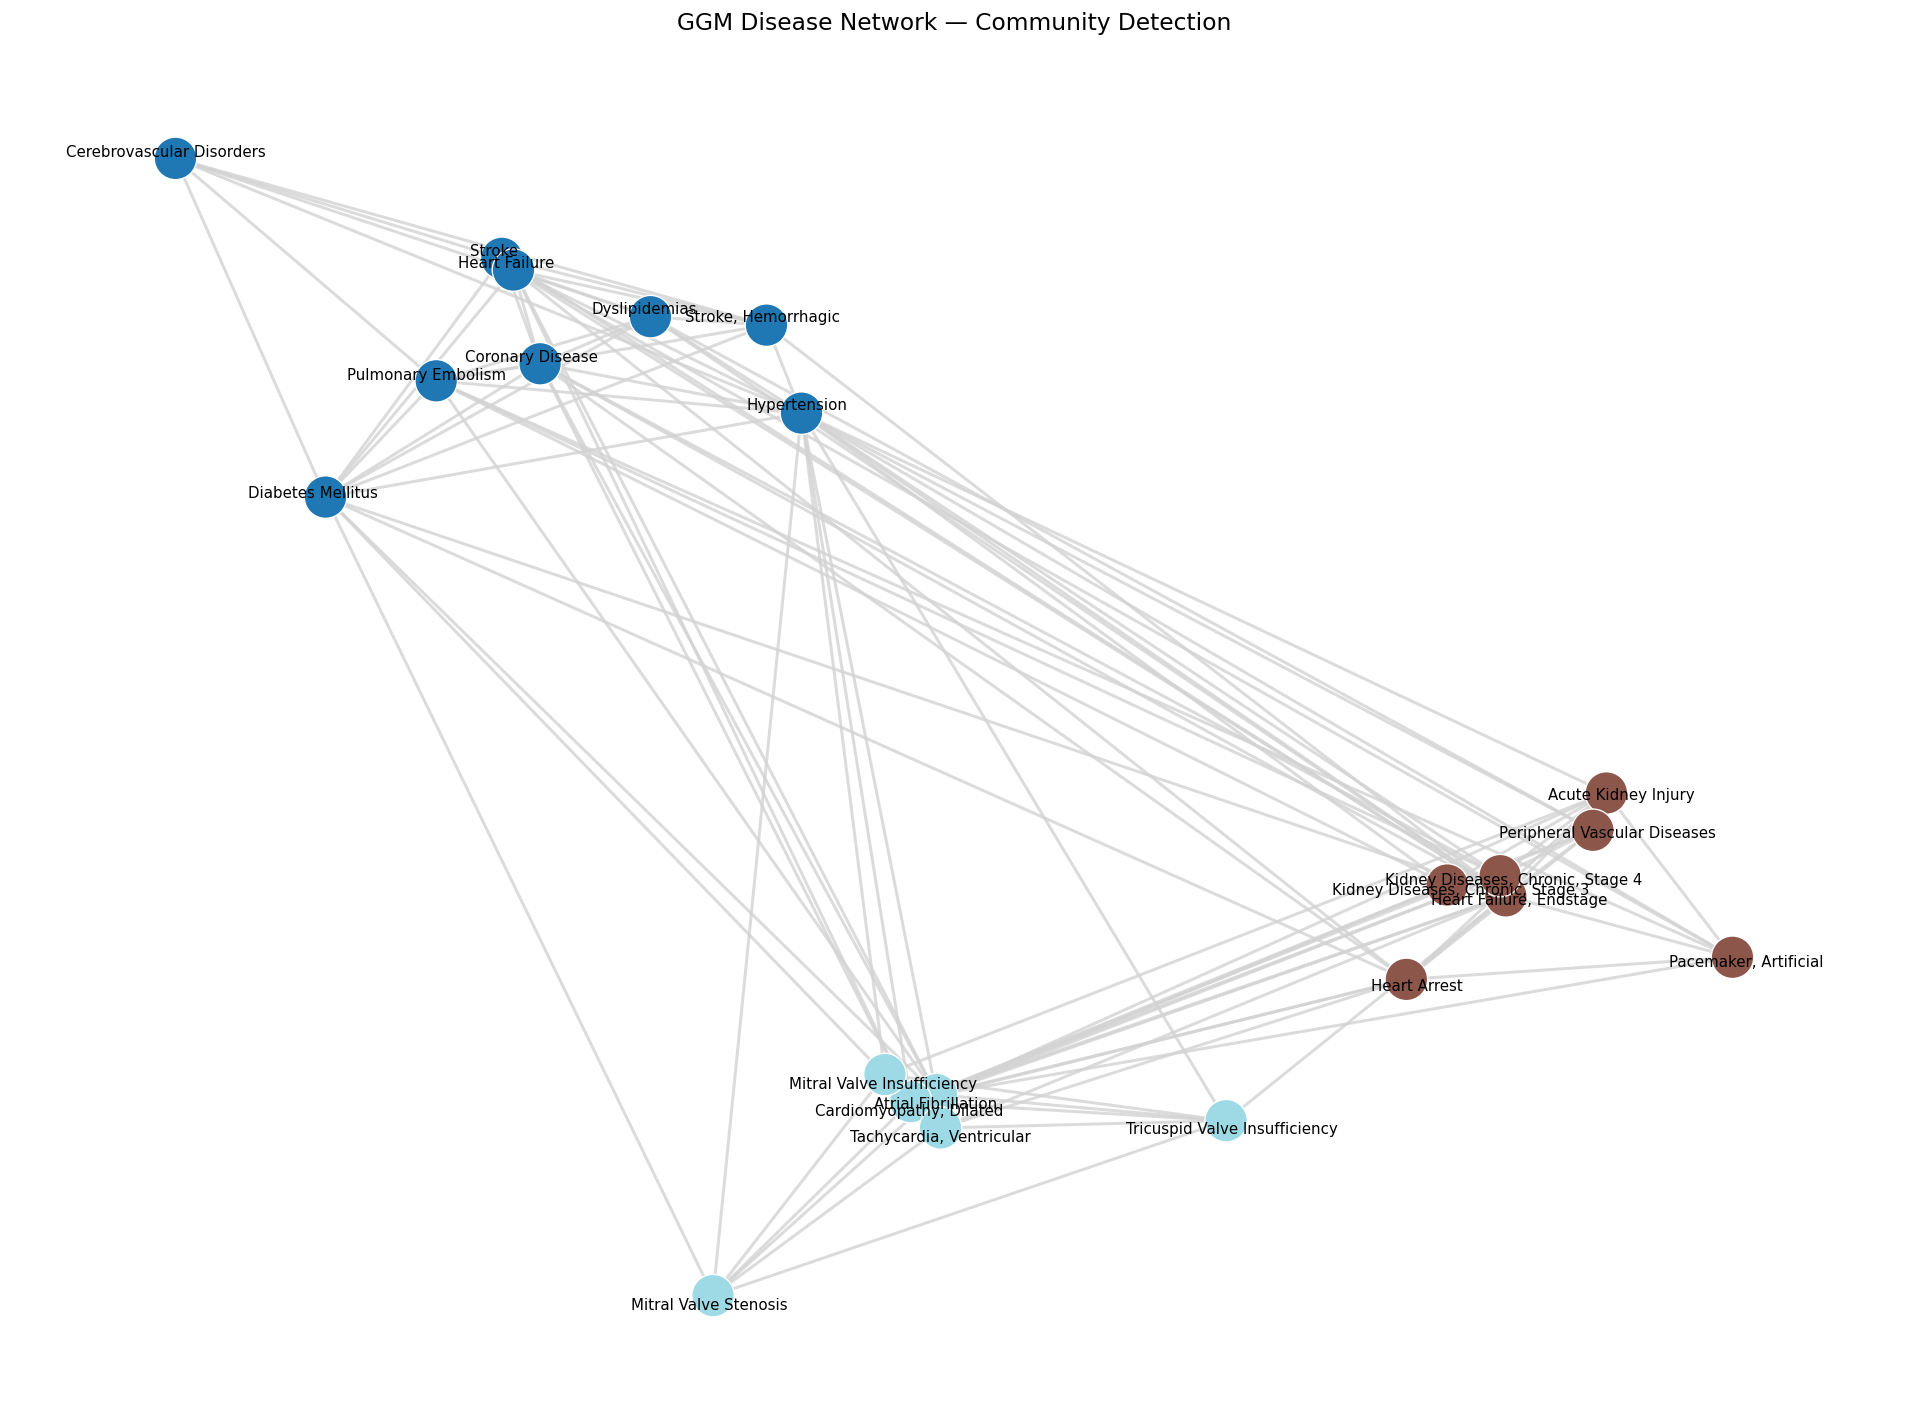

Saved: graph_GGM_by_community.svg


In [95]:
def plot_graph_by_community(G: nx.Graph,
                             community_df: pd.DataFrame,
                             layout: str = "kamada_kawai",
                             node_size: int = 650,
                             label_offset: float = 0.04,
                             edge_color: str = "lightgray",
                             edge_width: float = 1.8,
                             out: str = "graph_GGM_by_community.svg",
                             separate_communities: bool = True,
                             separation_strength: float = 1.8) -> None:
    """Community-coloured network plot (ported from Comorb_network_GGM_plot.ipynb)."""
    fig, ax = plt.subplots(figsize=(16, 12))

    if layout == "circular":
        pos = nx.circular_layout(G)
    elif layout == "spring":
        pos = nx.spring_layout(G, seed=1, k=0.9)
    else:
        pos = nx.kamada_kawai_layout(G)

    node_to_comm = dict(zip(community_df["Node"], community_df["cfg_community"]))

    if separate_communities:
        comm_nodes = {}
        for n in G.nodes():
            c = node_to_comm.get(n, -1)
            comm_nodes.setdefault(c, []).append(n)
        comm_centroid = {c: np.mean([pos[n] for n in ns], axis=0)
                        for c, ns in comm_nodes.items()}
        global_center = np.mean(list(pos.values()), axis=0)
        for c, nodes in comm_nodes.items():
            v    = comm_centroid[c] - global_center
            norm = np.linalg.norm(v)
            v    = v / norm if norm > 0 else np.array([1.0, 0.0])
            for n in nodes:
                pos[n] = pos[n] + separation_strength * v

    comms         = sorted({node_to_comm.get(n, -1) for n in G.nodes()})
    cmap_tab      = plt.colormaps["tab20"]
    comm_to_color = {c: cmap_tab(i / max(1, len(comms) - 1))
                     for i, c in enumerate(comms)}
    node_colors   = [comm_to_color[node_to_comm.get(n, -1)] for n in G.nodes()]

    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_color,
                            width=edge_width, alpha=0.8)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors,
                            node_size=node_size, linewidths=0.8,
                            edgecolors="white")
    center    = np.mean(list(pos.values()), axis=0)
    pos_labels = {}
    for n, (x, y) in pos.items():
        v  = np.array([x, y]) - center
        nn = np.linalg.norm(v)
        v  = v / nn if nn > 0 else np.array([1.0, 0.0])
        pos_labels[n] = (x + label_offset * v[0], y + label_offset * v[1])
    nx.draw_networkx_labels(G, pos_labels, ax=ax, font_size=9, font_color="black")

    ax.set_title("GGM Disease Network — Community Detection", fontsize=14)
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, out), format="svg", bbox_inches="tight")
    plt.savefig(os.path.join(OUTPUT_PLOTS_DIR, out.replace(".svg", ".pdf")),
                bbox_inches="tight")
    plt.show()
    print(f"Saved: {out}")


plot_graph_by_community(
    G_topo, topology_df,
    layout="kamada_kawai",
    separate_communities=True,
    separation_strength=1.8,
    out="graph_GGM_by_community.svg",
)
